In [1]:
%pip install neo4j
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "sheila123")

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Membuat node Person dan relationship KNOWS
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            """
            MERGE (a:Person {name: $name})
            MERGE (friend:Person {name: $friend_name})
            MERGE (a)-[:KNOWS]->(friend)
            """,
            name=name,
            friend_name=friend_name
        )

In [3]:
# Menampilkan daftar teman
def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            """
            MATCH (a:Person)-[:KNOWS]->(friend)
            WHERE a.name = $name
            RETURN friend.name AS friend_name
            ORDER BY friend.name
            """,
            name=name
        )

        for record in result:
            print(record["friend_name"])


# Membuat koneksi dan menjalankan program
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Daftar teman Arthur:")
    print_friends(driver, "Arthur")

Daftar teman Arthur:
Guinevere
Lancelot
Merlin


1. Apa nama database yang digunakan pada tutorial ini?

Nama database yang digunakan adalah neo4j.

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance!

- SHOW DATABASES — digunakan untuk menampilkan daftar database yang tersedia dalam satu instance Neo4j.
- CREATE DATABASE nama_database — digunakan untuk membuat database baru dalam satu instance Neo4j.
- MATCH (n) RETURN n — digunakan untuk mengambil dan menampilkan seluruh node beserta propertinya dari database yang sedang diakses.

3. Apa jenis graf pertemanan yang telah dibuat di sini?

Graf pertemanan yang dibuat merupakan graf berarah (directed graph) dengan model labeled property graph.

In [4]:
import os
import pandas as pd

events_path = r"events.csv"

df = pd.read_csv(events_path)

print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi dataset:")
df.info()

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


In [5]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()

    print("Constraint berhasil diperiksa!")


In [6]:
def import_batch(tx, batch):
    tx.run("""
        UNWIND $batch AS row

        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})

        WITH v, i, row
        CALL {
            WITH v, i, row
            WITH v, i, row WHERE row.event = 'view'
            CREATE (v)-[:VIEWED {
                eventId: row.event_id,
                timestamp: row.timestamp
            }]->(i)

            UNION ALL

            WITH v, i, row
            WITH v, i, row WHERE row.event = 'addtocart'
            CREATE (v)-[:ADDED_TO_CART {
                eventId: row.event_id,
                timestamp: row.timestamp
            }]->(i)

            UNION ALL

            WITH v, i, row
            WITH v, i, row WHERE row.event = 'transaction'
            CREATE (v)-[:BOUGHT {
                eventId: row.event_id,
                timestamp: row.timestamp,
                transactionId: row.transactionid
            }]->(i)
        }
    """, batch=batch).consume()


In [7]:

import os
import pandas as pd
from tqdm.notebook import tqdm
from neo4j import GraphDatabase

# Lokasi file events.csv
SOURCE = r"D:\Code-Sem7\Graf Sains Data"
csv_file_path = os.path.join(SOURCE, "events.csv")

# Koneksi Neo4j
URI = "neo4j://localhost:7687"
AUTH = ("neo4j", "sheila123")

driver = GraphDatabase.driver(URI, auth=AUTH)

# Cek koneksi
driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [8]:
batch_size = 10000

with open(csv_file_path, "r", encoding="utf-8-sig") as f:
    total_rows = max(sum(1 for _ in f) - 1, 0)

total_chunks = (total_rows + batch_size - 1) // batch_size

try:
    with driver.session(database="neo4j") as session:
        create_constraints(session)

        print(f"Membaca file data dari: {csv_file_path}")
        print(f"Total baris data: {total_rows}")
        print("Memulai proses impor data ke Neo4j...")

        chunks = pd.read_csv(csv_file_path, chunksize=batch_size)
        row_number = 0

        for chunk in tqdm(chunks, total=total_chunks,
                          desc="Mengimpor Batch Data"):

            # Membuat event_id untuk setiap baris
            chunk = chunk.reset_index(drop=True)
            chunk["event_id"] = range(
                row_number, row_number + len(chunk)
            )
            row_number += len(chunk)

            # Menangani nilai transactionid yang kosong
            chunk["transactionid"] = (
                chunk["transactionid"].fillna("").astype(str)
            )

            records = chunk.to_dict(orient="records")

            # Memastikan event_id tidak kosong
            assert all(
                record["event_id"] is not None
                for record in records
            ), "Ada event_id yang kosong!"

            import_batch(session, records)

        print("Proses impor berhasil!")

finally:
    driver.close()

Constraint berhasil diperiksa!
Membaca file data dari: D:\Code-Sem7\Graf Sains Data\events.csv
Total baris data: 2756101
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/276 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=8, column=9, offset=160>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 160, 'line': 8, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        UNWIND $batch AS row\n\n        MERGE (v:Visitor {visitorId: row.visitorid})\n        MERGE (i:Item {itemId: row.itemid})\n\n        WITH v, i, row\n        CALL {\n            WITH v, i, row\n            WITH v, i, row WHERE row.event = 'view'\n            CREATE (v)-[:VIEWED {\n                eventId: row.event_id,\n   

Proses impor berhasil!


In [9]:

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {
            eventId: row.event_id,
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {
            eventId: row.event_id,
            timestamp: row.timestamp
        }]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {
            eventId: row.event_id,
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    }
    """

    tx.run(cypher_query, batch=batch).consume()


# SOAL UTS

# 2.1 Wrangling dan EDA


### Nomor 1 — 2 periode waktu sebagai filter dari data interaksi

| Periode | Jenis Data | Tanggal Mulai | Tanggal Selesai |
|---|---|---|---|
| P1 | Fold Training | 1 Mei 2015 | 14 Mei 2025 |
| P2 | Fold Testing | 1 Juni 2015 | 7 Juni 2015 |


### Nomor 2 — Proses filter ini pada timestamp pada proses persiapan data

In [10]:
import os
import pandas as pd
import numpy as np

# Lokasi dataset
folder_path = r"D:\Code-Sem7\Graf Sains Data"
csv_file_path = os.path.join(folder_path, "events.csv")

# Membaca dataset
df = pd.read_csv(csv_file_path, encoding="utf-8-sig")

print("Ukuran dataset awal:", df.shape)
print("Nama kolom:", df.columns.tolist())

# Memastikan timestamp berupa angka Unix dalam milidetik
df["timestamp"] = pd.to_numeric(
    df["timestamp"], errors="coerce"
)

# Mengubah timestamp menjadi tanggal
df["datetime"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce"
)

# Periode P1: Fold Training
p1_start = pd.Timestamp("2015-05-01 00:00:00")
p1_end = pd.Timestamp("2025-05-14 23:59:59.999")

# Periode P2: Fold Testing
p2_start = pd.Timestamp("2015-06-01 00:00:00")
p2_end = pd.Timestamp("2015-06-07 23:59:59.999")

# Melakukan filtering
df_p1 = df[
    df["datetime"].between(p1_start, p1_end)
].copy()

df_p2 = df[
    df["datetime"].between(p2_start, p2_end)
].copy()

# Membuat ID event yang stabil untuk proses impor ke Neo4j
df_p1["event_id"] = df_p1.index.astype(int)
df_p2["event_id"] = df_p2.index.astype(int)

# Menyimpan CSV tanpa kolom datetime tambahan
p1_path = os.path.join(
    folder_path, "events_P1_training.csv"
)
p2_path = os.path.join(
    folder_path, "events_P2_testing.csv"
)

df_p1.drop(columns=["datetime"]).to_csv(
    p1_path, index=False, encoding="utf-8-sig"
)

df_p2.drop(columns=["datetime"]).to_csv(
    p2_path, index=False, encoding="utf-8-sig"
)

# Menampilkan hasil
print("\n--- HASIL FILTERING ---")
print("Jumlah baris P1:", len(df_p1))
print("Jumlah baris P2:", len(df_p2))
print("File P1:", p1_path)
print("File P2:", p2_path)

print("\nRentang tanggal P1:")
print(df_p1["datetime"].min(), "sampai", df_p1["datetime"].max())

print("\nRentang tanggal P2:")
print(df_p2["datetime"].min(), "sampai", df_p2["datetime"].max())

display(df_p1.head())
display(df_p2.head())


Ukuran dataset awal: (2756101, 5)
Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

--- HASIL FILTERING ---
Jumlah baris P1: 2756101
Jumlah baris P2: 146445
File P1: D:\Code-Sem7\Graf Sains Data\events_P1_training.csv
File P2: D:\Code-Sem7\Graf Sains Data\events_P2_testing.csv

Rentang tanggal P1:
2015-05-03 03:00:04.384000 sampai 2015-09-18 02:59:47.788000

Rentang tanggal P2:
2015-06-01 00:00:01.707000 sampai 2015-06-07 23:59:56.417000


,timestamp,visitorid,event,itemid,transactionid,datetime,event_id
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117,0
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164,1
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827,2
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914,3
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106,4


,timestamp,visitorid,event,itemid,transactionid,datetime,event_id
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117,0
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164,1
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827,2
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914,3
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106,4


### Nomor 3 — Komposisi subgraph dengan Python API Neo4j

In [11]:

import os
import pandas as pd
from neo4j import GraphDatabase
from tqdm.auto import tqdm

# Lokasi file CSV P1
SOURCE = r"D:\Code-Sem7\Graf Sains Data"
CSV_P1 = os.path.join(SOURCE, "events_P1_training.csv")

# Konfigurasi Neo4j
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "sheila123")

# Gunakan database yang memang kamu pakai
DATABASE = "neo4j"

BATCH_SIZE = 2000

# Validasi file
if not os.path.exists(CSV_P1):
    raise FileNotFoundError(
        f"File tidak ditemukan: {CSV_P1}"
    )

# Membuat koneksi
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Terhubung ke Neo4j.")
print("File P1 ditemukan:", CSV_P1)


def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()


with driver.session(database=DATABASE) as session:
    create_constraints(session)

print("Constraint Visitor dan Item berhasil diperiksa.")



Q_VIEW = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (v)-[r:VIEWED {eventId: row.event_id}]->(i)
SET r.timestamp = row.timestamp
"""

Q_CART = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (v)-[r:ADDED_TO_CART {eventId: row.event_id}]->(i)
SET r.timestamp = row.timestamp
"""

Q_BUY = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
MERGE (v)-[r:BOUGHT {eventId: row.event_id}]->(i)
SET r.timestamp = row.timestamp,
    r.transactionId = row.transactionid
"""

QUERIES = {
    "view": Q_VIEW,
    "addtocart": Q_CART,
    "transaction": Q_BUY
}


def import_batch(tx, query, batch):
    tx.run(query, batch=batch).consume()



def clean_txid(value):
    if pd.isna(value):
        return None
    return str(value)


total_rows = sum(
    1 for _ in open(CSV_P1, encoding="utf-8-sig")
) - 1

total_chunks = (total_rows + BATCH_SIZE - 1) // BATCH_SIZE

print("Total baris P1:", total_rows)
print("Total batch:", total_chunks)

with driver.session(database=DATABASE) as session:
    run_write = (
        getattr(session, "execute_write", None)
        or session.write_transaction
    )

    for chunk in tqdm(
        pd.read_csv(CSV_P1, chunksize=BATCH_SIZE, encoding="utf-8-sig"),
        total=total_chunks,
        desc="Impor P1"
    ):
        # Pastikan kolom ID tersedia
        required_columns = {
            "timestamp", "visitorid", "event",
            "itemid", "transactionid", "event_id"
        }

        missing = required_columns - set(chunk.columns)
        if missing:
            raise ValueError(
                f"Kolom CSV tidak ditemukan: {missing}"
            )

        # Membersihkan tipe data
        chunk = chunk.dropna(
            subset=["timestamp", "visitorid", "itemid", "event_id"]
        ).copy()

        for col in ["timestamp", "visitorid", "itemid", "event_id"]:
            chunk[col] = pd.to_numeric(
                chunk[col], errors="raise"
            ).astype("int64")

        chunk["transactionid"] = (
            chunk["transactionid"].apply(clean_txid)
        )

        for event, query in QUERIES.items():
            rows = chunk.loc[
                chunk["event"] == event,
                [
                    "timestamp", "visitorid", "itemid",
                    "event_id", "transactionid"
                ]
            ].to_dict(orient="records")

            if rows:
                run_write(import_batch, query, rows)

print("Impor data P1 selesai.")



def run_query(query):
    with driver.session(database=DATABASE) as session:
        return [
            record.data()
            for record in session.run(query)
        ]


q_nodes = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul,
       count(n) AS jumlah
ORDER BY jumlah DESC
"""

df_nodes = pd.DataFrame(run_query(q_nodes))

print("=== Jumlah simpul per jenis ===")
display(df_nodes)



q_rels = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi,
       count(r) AS jumlah
ORDER BY jumlah DESC
"""

df_rels = pd.DataFrame(run_query(q_rels))

print("=== Jumlah relasi per jenis ===")
display(df_rels)

print("Total relasi:", df_rels["jumlah"].sum())



q_pattern = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari,
       type(r) AS relasi,
       labels(b)[0] AS ke,
       count(*) AS jumlah
ORDER BY jumlah DESC
"""

df_pattern = pd.DataFrame(run_query(q_pattern))

print("=== Pola hubungan graf ===")
display(df_pattern)



p1 = pd.read_csv(CSV_P1, encoding="utf-8-sig")

validasi = pd.DataFrame({
    "Neo4j": [
        int(
            df_nodes.loc[
                df_nodes["jenis_simpul"] == "Visitor", "jumlah"
            ].sum()
        ),
        int(
            df_nodes.loc[
                df_nodes["jenis_simpul"] == "Item", "jumlah"
            ].sum()
        )
    ],
    "Pandas": [
        int(p1["visitorid"].nunique()),
        int(p1["itemid"].nunique())
    ]
}, index=["Visitor", "Item"])

print("=== Validasi jumlah simpul ===")
display(validasi)

print("=== Jumlah event pada CSV P1 ===")
display(p1["event"].value_counts())

print("=== Total relasi Neo4j ===")
print(df_rels["jumlah"].sum())


Terhubung ke Neo4j.
File P1 ditemukan: D:\Code-Sem7\Graf Sains Data\events_P1_training.csv
Constraint Visitor dan Item berhasil diperiksa.
Total baris P1: 2756101
Total batch: 1379


Impor P1:   0%|          | 0/1379 [00:00<?, ?it/s]

Impor data P1 selesai.
=== Jumlah simpul per jenis ===


,jenis_simpul,jumlah
0,Visitor,1407580
1,Item,235061
2,Person,4


=== Jumlah relasi per jenis ===


...

=== Validasi jumlah simpul ===


,Neo4j,Pandas
Visitor,1407580,1407580
Item,235061,235061


=== Jumlah event pada CSV P1 ===


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

=== Total relasi Neo4j ===
10604448


## Penjelasan Sintaks Cypher

**1. Mengidentifikasi jumlah simpul berdasarkan label**

```cypher
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC;
```

Perintah `MATCH (n)` digunakan untuk mengambil seluruh simpul yang terdapat dalam database. Fungsi `labels(n)[0]` menampilkan label pertama dari setiap simpul, sedangkan `count(n)` menghitung banyaknya simpul untuk setiap label. Hasilnya dikelompokkan berdasarkan jenis simpul dan diurutkan dari jumlah terbanyak. Query ini membantu mengetahui komposisi entitas yang telah terbentuk di dalam graf.

**2. Menghitung relasi berdasarkan jenis interaksi**

```cypher
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC;
```

Query tersebut mengambil seluruh relasi berarah yang tersimpan di dalam database. Fungsi `type(r)` digunakan untuk mengidentifikasi jenis hubungan, seperti `VIEWED`, `ADDED_TO_CART`, `BOUGHT`, dan `KNOWS`. Selanjutnya, `count(r)` menghitung jumlah relasi untuk setiap jenisnya. Hasil ini dapat digunakan untuk melihat hubungan mana yang paling banyak terbentuk dalam graf.

**3. Mengidentifikasi pola hubungan antarsimpul**

```cypher
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS dari,
       type(r) AS relasi,
       labels(b)[0] AS ke,
       count(*) AS jumlah
ORDER BY jumlah DESC;
```

Query ini digunakan untuk melihat kombinasi label simpul asal, tipe relasi, dan label simpul tujuan. Variabel `a` dan `b` mewakili simpul yang saling terhubung, sedangkan `r` merepresentasikan relasi di antara keduanya. Fungsi `count(*)` menghitung jumlah hubungan untuk setiap kombinasi pola tersebut. Dengan demikian, struktur koneksi dalam graf dapat diketahui tanpa harus memeriksa setiap relasi secara manual.

**4. Mengurutkan hasil analisis**

```cypher
ORDER BY jumlah DESC
```

Klausa `ORDER BY` mengatur urutan tampilan hasil berdasarkan kolom yang ditentukan. Penggunaan `DESC` menghasilkan urutan menurun, sehingga entitas atau relasi dengan jumlah terbesar muncul terlebih dahulu. Pengurutan ini memudahkan identifikasi pola yang paling dominan dalam hasil analisis.

## Hasil Proses Impor dan Validasi Data

Proses impor dilakukan menggunakan file `events_P1_training.csv` yang berisi **2.756.101 baris data**. Data dimasukkan ke Neo4j secara bertahap dalam 1.379 batch. Proses tersebut selesai hingga mencapai 100%, sehingga seluruh batch yang dijadwalkan telah diproses oleh program.

Hasil pemeriksaan jumlah simpul menunjukkan bahwa terdapat 1.407.580 simpul `Visitor` dan 235.061 simpul `Item`. Kedua jumlah tersebut sama dengan hasil penghitungan menggunakan Pandas pada file CSV P1. Kesesuaian ini menunjukkan bahwa jumlah identitas visitor dan item yang terbentuk di Neo4j sudah sesuai dengan data sumber.

Meskipun demikian, jumlah relasi masih menunjukkan perbedaan. Jumlah event yang terdapat pada CSV P1 adalah 2.664.312 event `view`, 69.332 event `addtocart`, dan 22.457 event `transaction`. Sementara itu, Neo4j mencatat jumlah relasi yang lebih besar untuk ketiga jenis interaksi tersebut.

Perbedaan ini perlu diperiksa sebelum menyimpulkan bahwa proses impor sepenuhnya valid. Salah satu kemungkinan penyebabnya adalah adanya relasi dari proses impor sebelumnya yang belum terhapus atau tidak dikenali sebagai relasi yang sama ketika proses impor dijalankan kembali. Oleh sebab itu, validasi jumlah simpul saja belum cukup untuk memastikan bahwa seluruh relasi telah sesuai dengan CSV.

## Komposisi Simpul

Berdasarkan hasil query Neo4j, komposisi simpul yang ditemukan adalah sebagai berikut.

| Jenis simpul | Jumlah |
|---|---:|
| `Visitor` | 1.407.580 |
| `Item` | 235.061 |
| `Person` | 4 |
| **Total** | **1.642.645** |

Simpul `Visitor` merupakan kelompok terbesar, diikuti oleh simpul `Item`. Perbandingan jumlah `Visitor` terhadap `Item` sekitar 5,99 : 1. Hal ini memperlihatkan bahwa jumlah identitas pengguna yang tercatat dalam dataset jauh lebih banyak daripada jumlah produk yang teridentifikasi.

Selain kedua jenis simpul tersebut, terdapat empat simpul berlabel `Person`. Simpul ini tidak termasuk ke dalam model interaksi utama dataset RetailRocket. Keberadaannya kemungkinan berkaitan dengan data dari latihan atau proses sebelumnya yang masih tersimpan dalam database. Oleh karena itu, simpul tersebut perlu diperiksa agar tidak tercampur dengan hasil analisis graf interaksi e-commerce.

## Komposisi Relasi

Hasil penghitungan relasi di Neo4j ditampilkan pada tabel berikut.

| Jenis relasi | Jumlah di Neo4j |
|---|---:|
| `VIEWED` | 3.949.246 |
| `ADDED_TO_CART` | 103.431 |
| `BOUGHT` | 33.424 |
| `KNOWS` | 3 |
| **Total** | **4.086.104** |

Relasi `VIEWED` memiliki jumlah paling besar dibandingkan jenis relasi lainnya. Hal ini sesuai dengan karakteristik aktivitas e-commerce, ketika pengguna lebih sering melihat produk dibandingkan menambahkan produk ke keranjang atau melakukan pembelian. Relasi `ADDED_TO_CART` dan `BOUGHT` memiliki jumlah yang lebih kecil, sedangkan `KNOWS` merupakan relasi yang berbeda dari pola interaksi pengguna terhadap produk.

Namun, angka pada tabel merupakan jumlah relasi yang saat ini terbaca dalam database, bukan jumlah event unik yang telah dipastikan berasal dari CSV P1. Hal ini karena jumlah relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` semuanya lebih besar daripada jumlah event masing-masing pada file sumber.

Untuk memperjelas perbedaannya, perbandingan jumlah event CSV dengan relasi Neo4j adalah sebagai berikut.

| Jenis event | CSV P1 | Relasi Neo4j | Selisih |
|---|---:|---:|---:|
| `view` / `VIEWED` | 2.664.312 | 3.949.246 | 1.284.934 |
| `addtocart` / `ADDED_TO_CART` | 69.332 | 103.431 | 34.099 |
| `transaction` / `BOUGHT` | 22.457 | 33.424 | 10.967 |
| **Total interaksi** | **2.756.101** | **4.086.101** | **1.330.000** |

Tabel tersebut menunjukkan adanya kelebihan sebanyak 1.330.000 relasi interaksi dibandingkan jumlah baris event pada CSV P1. Dengan demikian, database perlu diperiksa lebih lanjut sebelum hasil komposisi relasi digunakan sebagai representasi final dari dataset.

## Pola Hubungan dalam Graf

Hasil pemeriksaan pola hubungan menunjukkan dua struktur utama yang tersimpan dalam database.

- `Visitor` → `VIEWED` → `Item`
- `Visitor` → `ADDED_TO_CART` → `Item`
- `Visitor` → `BOUGHT` → `Item`
- `Person` → `KNOWS` → `Person`

Tiga pola pertama merepresentasikan aktivitas pengguna terhadap produk. Melalui relasi tersebut, graf dapat menyimpan informasi mengenai produk yang dilihat, dimasukkan ke keranjang, maupun dibeli oleh pengguna. Informasi ini dapat dimanfaatkan untuk membentuk matriks interaksi antara pengguna dan produk pada tahap analisis berikutnya.

Sementara itu, pola `Person` → `KNOWS` → `Person` tidak mengikuti struktur interaksi utama RetailRocket. Pola tersebut kemungkinan berasal dari data lain yang masih terdapat dalam database. Jika analisis selanjutnya ditujukan khusus untuk dataset RetailRocket, relasi dan simpul tambahan ini perlu dipisahkan atau dibersihkan terlebih dahulu.

Secara konseptual, graf interaksi RetailRocket merupakan **graf bipartit berarah**, karena terdiri atas dua kelompok simpul utama, yaitu `Visitor` dan `Item`, dengan arah hubungan dari pengguna menuju produk. Tidak terdapat kebutuhan untuk membentuk hubungan langsung antara dua simpul `Visitor` atau antara dua simpul `Item` pada tahap pembentukan graf awal.

Struktur tersebut menjadi dasar untuk melakukan proyeksi graf pada tahap berikutnya. Melalui proyeksi, pengguna yang berinteraksi dengan produk yang sama dapat digunakan untuk menghitung kemiripan antarproduk, atau produk yang sama dapat menjadi dasar untuk menghitung kemiripan antar pengguna. Hasilnya kemudian dapat dimanfaatkan dalam analisis rekomendasi berbasis graf.

## Kesimpulan

Pembentukan graf di Neo4j telah menghasilkan simpul `Visitor` dan `Item` dengan jumlah yang sesuai dengan hasil validasi Pandas. Relasi interaksi juga telah terbentuk dalam tiga jenis utama, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`.

Akan tetapi, terdapat dua hal yang perlu diperhatikan sebelum melanjutkan analisis. Pertama, database masih memuat empat simpul `Person` beserta tiga relasi `KNOWS` yang tidak termasuk dalam pola interaksi utama RetailRocket. Kedua, jumlah relasi interaksi di Neo4j melebihi jumlah event dalam CSV P1 sebanyak 1.330.000 relasi.

Oleh karena itu, pemeriksaan dan pembersihan relasi perlu dilakukan agar graf yang digunakan pada tahap proyeksi dan perhitungan kemiripan benar-benar merepresentasikan data P1. Setelah jumlah relasi sesuai dengan data sumber, graf tersebut dapat digunakan sebagai dasar analisis kemiripan antarvisitor atau antaritem.

### Nomor 4 — VSM pada simpul User/Visitor

HASIL SOAL 4: VSM USER
Dimensi matriks       : 2
Shape matriks         : (1407580, 235061)
Jumlah User           : 1407580
Jumlah Item           : 235061
Jumlah elemen nonzero : 2145179
Density               : 0.00064835%
Sparsity              : 99.99935165%
Estimasi memori dense : 2465.1525 GB
Memori sparse         : 29.92 MB
Rata-rata item/User   : 1.52
Median item/User      : 1.00
Maksimum item/User    : 3814

Contoh matriks (5 User × 5 Item):
   67045   285930  357564  72028   216305
0     3.0     3.0     3.0     0.0     0.0
1     0.0     0.0     0.0     4.0     0.0
2     0.0     0.0     0.0     0.0     8.0
3     0.0     0.0     0.0     0.0     0.0
4     0.0     0.0     0.0     0.0     0.0


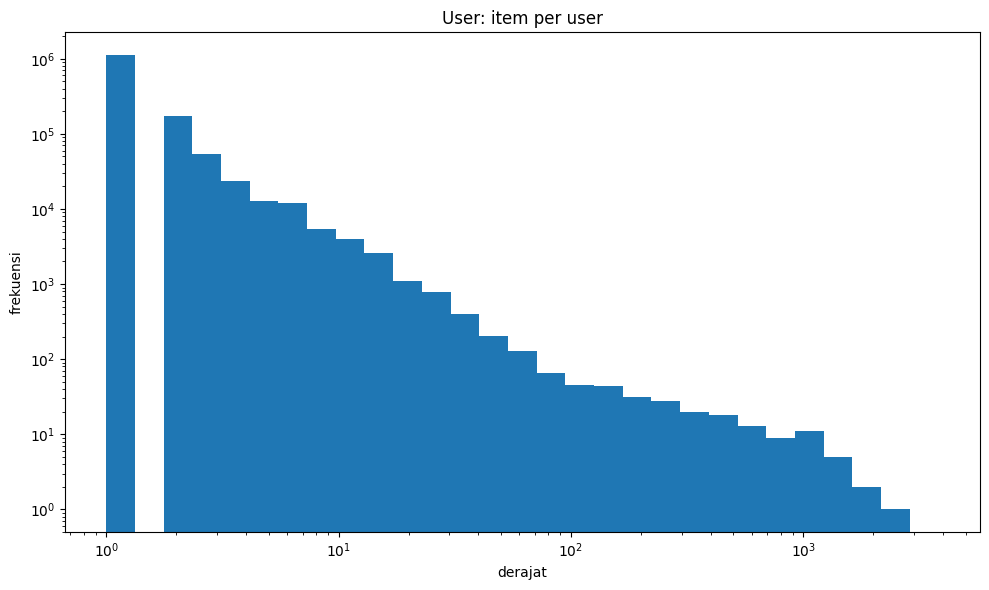

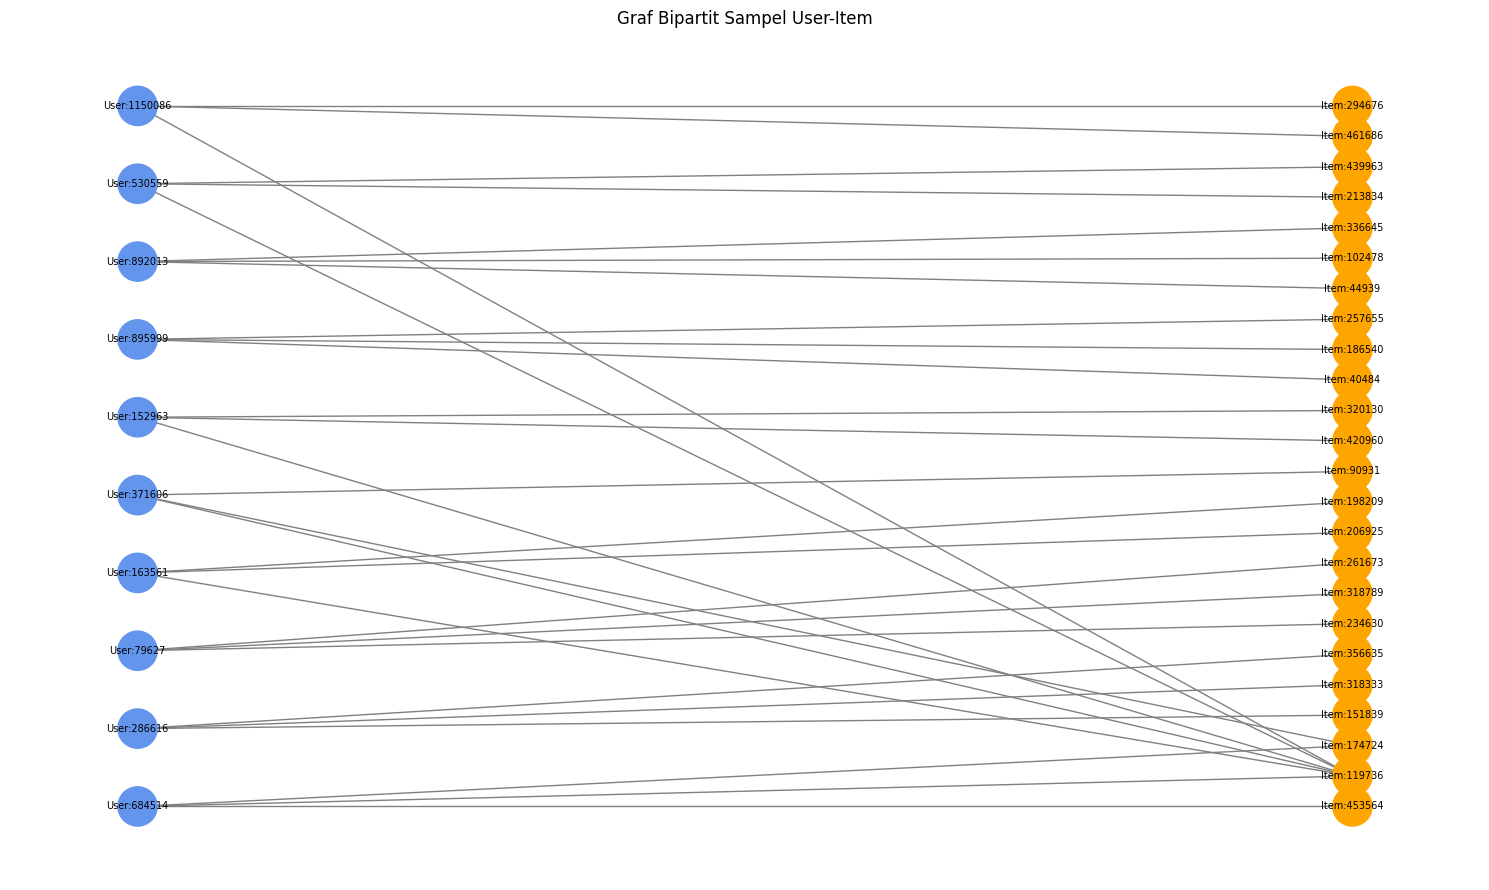


Jumlah node pada graf sampel: 34
Jumlah edge pada graf sampel: 30

File VSM User tersimpan di: D:\Code-Sem7\Graf Sains Data


In [12]:
# ============================================================
# SOAL 4: VECTOR SPACE MODELING (VSM) UNTUK USER
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import csr_matrix, save_npz
from neo4j import GraphDatabase

# 1. Konfigurasi
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "sheila123")
DATABASE = "neo4j"
SOURCE = r"D:\Code-Sem7\Graf Sains Data"

os.makedirs(SOURCE, exist_ok=True)

# 2. Ambil interaksi User-Item dari Neo4j
query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    v.visitorId AS user_id,
    i.itemId AS item_id,
    sum(
        CASE type(r)
            WHEN 'VIEWED' THEN 1
            WHEN 'ADDED_TO_CART' THEN 3
            WHEN 'BOUGHT' THEN 5
            ELSE 0
        END
    ) AS bobot
"""

driver = GraphDatabase.driver(URI, auth=AUTH)

try:
    driver.verify_connectivity()
    with driver.session(database=DATABASE) as session:
        records = list(session.run(query))
finally:
    driver.close()

if not records:
    raise ValueError(
        "Data interaksi tidak ditemukan. Periksa database dan struktur graf."
    )

df = pd.DataFrame([r.data() for r in records])
df = df.dropna(subset=["user_id", "item_id", "bobot"])
df["bobot"] = pd.to_numeric(df["bobot"], errors="coerce")
df = df.dropna(subset=["bobot"])
df = df[df["bobot"] > 0]

# Gabungkan pasangan User-Item jika terdapat duplikasi
df = df.groupby(
    ["user_id", "item_id"], as_index=False
)["bobot"].sum()

# 3. Bentuk matriks User × Item
user_ids = pd.Index(df["user_id"].unique())
item_ids = pd.Index(df["item_id"].unique())

user_map = {v: i for i, v in enumerate(user_ids)}
item_map = {v: i for i, v in enumerate(item_ids)}

rows = df["user_id"].map(user_map).to_numpy()
cols = df["item_id"].map(item_map).to_numpy()
values = df["bobot"].to_numpy(dtype=np.float64)

VSM_User = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids))
)

# Simpan matriks dan ID untuk Soal 5
save_npz(os.path.join(SOURCE, "VSM_User_P1.npz"), VSM_User)
np.save(os.path.join(SOURCE, "user_ids_P1.npy"), user_ids.to_numpy())
np.save(os.path.join(SOURCE, "item_ids_P1.npy"), item_ids.to_numpy())

# 4. Analisis karakteristik matriks
n_user, n_item = VSM_User.shape
total_elemen = n_user * n_item
nnz = VSM_User.nnz

density = nnz / total_elemen if total_elemen else 0
sparsity = 1 - density

dense_bytes = total_elemen * VSM_User.dtype.itemsize
sparse_bytes = (
    VSM_User.data.nbytes
    + VSM_User.indices.nbytes
    + VSM_User.indptr.nbytes
)

item_per_user = np.diff(VSM_User.indptr)

print("=" * 60)
print("HASIL SOAL 4: VSM USER")
print("=" * 60)
print("Dimensi matriks       :", VSM_User.ndim)
print("Shape matriks         :", VSM_User.shape)
print("Jumlah User           :", n_user)
print("Jumlah Item           :", n_item)
print("Jumlah elemen nonzero :", nnz)
print(f"Density               : {density:.8%}")
print(f"Sparsity              : {sparsity:.8%}")
print(f"Estimasi memori dense : {dense_bytes / 1024**3:.4f} GB")
print(f"Memori sparse         : {sparse_bytes / 1024**2:.2f} MB")
print(f"Rata-rata item/User   : {item_per_user.mean():.2f}")
print(f"Median item/User      : {np.median(item_per_user):.2f}")
print(f"Maksimum item/User    : {item_per_user.max()}")

print("\nContoh matriks (5 User × 5 Item):")
print(pd.DataFrame(
    VSM_User[:5, :5].toarray(),
    index=user_ids[:5],
    columns=item_ids[:5]
))

# 5. Plot distribusi jumlah Item per User
degree = item_per_user
degree = degree[degree > 0]

plt.figure(figsize=(10, 6))
plt.hist(
    degree,
    bins=np.logspace(
        np.log10(degree.min()),
        np.log10(degree.max()),
        30
    ),
    edgecolor="none"
)
plt.xscale("log")
plt.yscale("log")
plt.title("User: item per user")
plt.xlabel("derajat")
plt.ylabel("frekuensi")
plt.tight_layout()
plt.show()

# 6. Visualisasi graf bipartit User-Item
# PERBAIKAN: pilih User dengan derajat tertinggi,
# lalu pilih maksimal 3 Item per User berdasarkan bobot.
kandidat = np.flatnonzero(item_per_user > 0)
selected_users = kandidat[
    np.argsort(item_per_user[kandidat])[-10:]
]

G = nx.Graph()

for u in selected_users:
    user_node = f"User:{user_ids[u]}"
    G.add_node(user_node, bipartite=0, tipe="User")

    start, end = VSM_User.indptr[u], VSM_User.indptr[u + 1]
    indices = VSM_User.indices[start:end]
    weights = VSM_User.data[start:end]

    top = np.argsort(weights)[-3:]

    for p in top:
        i = indices[p]
        item_node = f"Item:{item_ids[i]}"
        G.add_node(item_node, bipartite=1, tipe="Item")
        G.add_edge(user_node, item_node, weight=float(weights[p]))

if G.number_of_edges() > 0:
    user_nodes = [
        n for n, d in G.nodes(data=True) if d["tipe"] == "User"
    ]
    pos = nx.bipartite_layout(G, user_nodes)

    colors = [
        "cornflowerblue" if G.nodes[n]["tipe"] == "User"
        else "orange"
        for n in G.nodes()
    ]

    plt.figure(figsize=(15, 9))
    nx.draw_networkx(
        G, pos,
        with_labels=True,
        node_color=colors,
        node_size=800,
        font_size=7,
        edge_color="gray"
    )
    plt.title("Graf Bipartit Sampel User-Item")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("\nJumlah node pada graf sampel:", G.number_of_nodes())
    print("Jumlah edge pada graf sampel:", G.number_of_edges())
else:
    print("Tidak ada edge untuk divisualisasikan.")

print("\nFile VSM User tersimpan di:", SOURCE)

Pada soal ini, pendekatan **Vector Space Model (VSM)** diterapkan dari sudut pandang User. Matriks User–Item yang dibentuk merepresentasikan setiap pengguna sebagai satu vektor, sedangkan setiap kolom merepresentasikan produk yang berinteraksi dengan pengguna tersebut. Nilai pada matriks menunjukkan bobot interaksi antara pengguna dan produk, dengan bobot yang lebih besar menunjukkan akumulasi interaksi yang lebih tinggi.

Berdasarkan hasil pengolahan data, matriks VSM User memiliki **shape sebesar 1.407.580 × 235.061**, yang berarti terdapat 1.407.580 pengguna dengan 235.061 dimensi produk. Matriks tersebut memiliki **2.145.179 elemen non-zero (nnz)**, dengan nilai density sebesar **0,00064835%** dan sparsity sebesar **99,99935165%**. Tingginya nilai sparsity menunjukkan bahwa sebagian besar kombinasi pengguna dan produk tidak memiliki interaksi yang tercatat. Oleh karena itu, representasi sparse digunakan agar penyimpanan matriks lebih efisien. Matriks sparse membutuhkan memori sekitar **29,92 MB**, sedangkan estimasi kebutuhan memori untuk representasi dense mencapai **2.465,15 GB**.

Karakteristik interaksi pengguna juga terlihat dari jumlah produk unik yang terhubung dengan setiap pengguna. Rata-rata jumlah produk per pengguna adalah **1,52**, dengan median **1 produk** dan jumlah maksimum **3.814 produk**. Hasil tersebut menunjukkan bahwa sebagian besar pengguna berinteraksi dengan sedikit produk, sedangkan sebagian kecil pengguna memiliki interaksi dengan jauh lebih banyak produk.

Visualisasi subgraf bipartit menggunakan NetworkX memperlihatkan hubungan antara pengguna dan produk yang berinteraksi dengannya. Simpul berwarna biru merepresentasikan User, sedangkan simpul berwarna oranye merepresentasikan Item. Garis penghubung menunjukkan adanya interaksi antara pengguna dan produk. Pada visualisasi yang dihasilkan, graf sampel terdiri atas **34 simpul dan 30 sisi**. Graf ini merupakan sampel hubungan yang dipilih untuk memudahkan pengamatan, bukan keseluruhan graf dari semua pengguna dan produk.

### Nomor 5 — VSM dengan simpul Item

HASIL SOAL 5: VSM ITEM
Dimensi matriks       : 2
Shape matriks         : (235061, 1407580)
Jumlah Item           : 235061
Jumlah User           : 1407580
Jumlah elemen nonzero : 2145179
Density               : 0.00064835%
Sparsity              : 99.99935165%
Estimasi memori dense : 2465.1525 GB
Memori sparse         : 25.45 MB
Rata-rata User/Item   : 9.13
Median User/Item      : 2.00
Maksimum User/Item    : 2912

Contoh matriks (5 Item × 5 User):
          0    1    2    3    4
67045   3.0  0.0  0.0  0.0  0.0
285930  3.0  0.0  0.0  0.0  0.0
357564  3.0  0.0  0.0  0.0  0.0
72028   0.0  4.0  0.0  0.0  0.0
216305  0.0  0.0  8.0  0.0  0.0


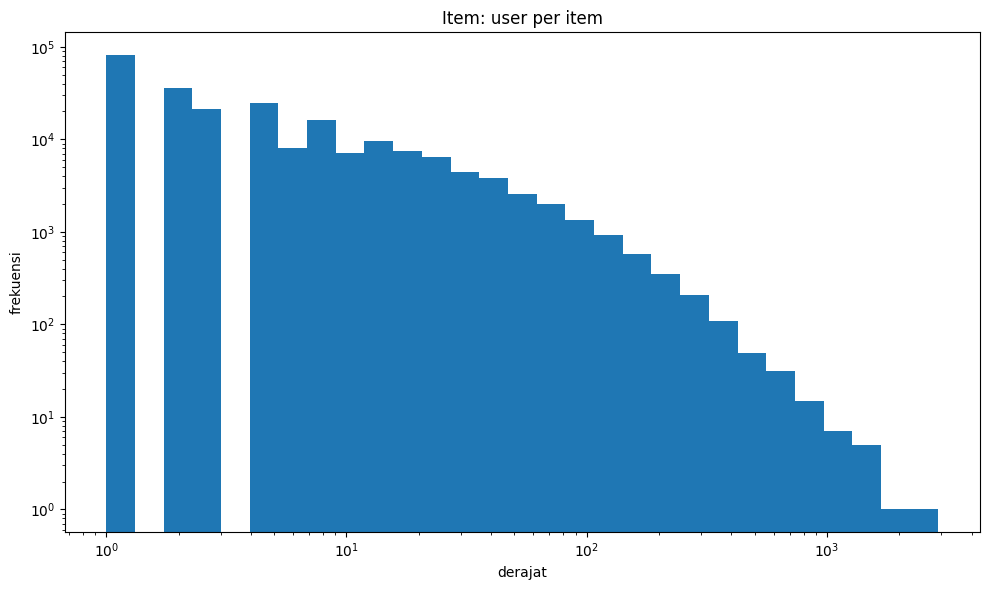

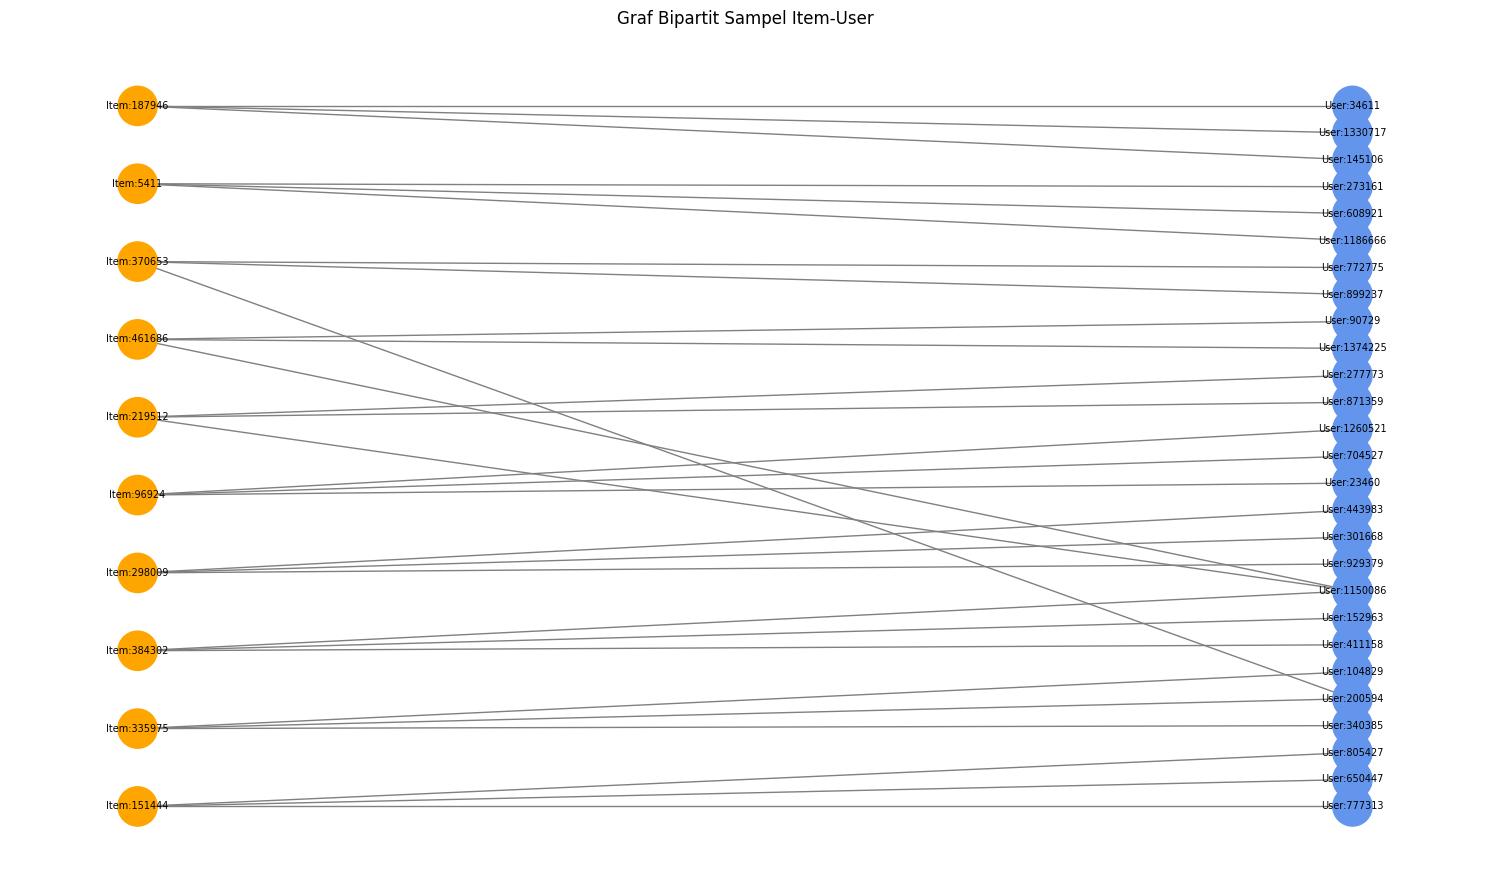


Jumlah node pada graf sampel: 37
Jumlah edge pada graf sampel: 30

VALIDASI TRANSPOSE
Shape VSM User : (1407580, 235061)
Shape VSM Item : (235061, 1407580)
Jumlah nnz User: 2145179
Jumlah nnz Item: 2145179
Apakah nnz sama: True

File VSM Item tersimpan di: D:\Code-Sem7\Graf Sains Data


In [13]:
# ============================================================
# SOAL 5: VECTOR SPACE MODELING (VSM) UNTUK ITEM
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from scipy.sparse import load_npz, save_npz

# 1. Konfigurasi folder hasil
SOURCE = r"D:\Code-Sem7\Graf Sains Data"
os.makedirs(SOURCE, exist_ok=True)

# 2. Muat matriks User dari Soal 4
path_user = os.path.join(SOURCE, "VSM_User_P1.npz")
path_users = os.path.join(SOURCE, "user_ids_P1.npy")
path_items = os.path.join(SOURCE, "item_ids_P1.npy")

if not all(os.path.exists(p) for p in [path_user, path_users, path_items]):
    raise FileNotFoundError(
        "File hasil Soal 4 belum ditemukan. Jalankan Soal 4 terlebih dahulu."
    )

VSM_User = load_npz(path_user).tocsr()
user_ids = np.load(path_users, allow_pickle=True)
item_ids = np.load(path_items, allow_pickle=True)

# 3. Transposisi: Item × User
VSM_Item = VSM_User.transpose().tocsr()

# Simpan matriks Item
save_npz(os.path.join(SOURCE, "VSM_Item_P1.npz"), VSM_Item)

# 4. Analisis karakteristik matriks
n_item, n_user = VSM_Item.shape
total_elemen = n_item * n_user
nnz = VSM_Item.nnz

density = nnz / total_elemen if total_elemen else 0
sparsity = 1 - density

dense_bytes = total_elemen * VSM_Item.dtype.itemsize
sparse_bytes = (
    VSM_Item.data.nbytes
    + VSM_Item.indices.nbytes
    + VSM_Item.indptr.nbytes
)

user_per_item = np.diff(VSM_Item.indptr)

print("=" * 60)
print("HASIL SOAL 5: VSM ITEM")
print("=" * 60)
print("Dimensi matriks       :", VSM_Item.ndim)
print("Shape matriks         :", VSM_Item.shape)
print("Jumlah Item           :", n_item)
print("Jumlah User           :", n_user)
print("Jumlah elemen nonzero :", nnz)
print(f"Density               : {density:.8%}")
print(f"Sparsity              : {sparsity:.8%}")
print(f"Estimasi memori dense : {dense_bytes / 1024**3:.4f} GB")
print(f"Memori sparse         : {sparse_bytes / 1024**2:.2f} MB")
print(f"Rata-rata User/Item   : {user_per_item.mean():.2f}")
print(f"Median User/Item      : {np.median(user_per_item):.2f}")
print(f"Maksimum User/Item    : {user_per_item.max()}")

print("\nContoh matriks (5 Item × 5 User):")
print(pd.DataFrame(
    VSM_Item[:5, :5].toarray(),
    index=item_ids[:5],
    columns=user_ids[:5]
))

# 5. Plot distribusi jumlah User per Item
degree = user_per_item
degree = degree[degree > 0]

plt.figure(figsize=(10, 6))
plt.hist(
    degree,
    bins=np.logspace(
        np.log10(degree.min()),
        np.log10(degree.max()),
        30
    ),
    edgecolor="none"
)
plt.xscale("log")
plt.yscale("log")
plt.title("Item: user per item")
plt.xlabel("derajat")
plt.ylabel("frekuensi")
plt.tight_layout()
plt.show()

# 6. Visualisasi graf bipartit Item-User
# PERBAIKAN: pilih Item dengan derajat tertinggi,
# lalu pilih maksimal 3 User per Item berdasarkan bobot.
kandidat = np.flatnonzero(user_per_item > 0)
selected_items = kandidat[
    np.argsort(user_per_item[kandidat])[-10:]
]

G = nx.Graph()

for i in selected_items:
    item_node = f"Item:{item_ids[i]}"
    G.add_node(item_node, bipartite=0, tipe="Item")

    start, end = VSM_Item.indptr[i], VSM_Item.indptr[i + 1]
    indices = VSM_Item.indices[start:end]
    weights = VSM_Item.data[start:end]

    top = np.argsort(weights)[-3:]

    for p in top:
        u = indices[p]
        user_node = f"User:{user_ids[u]}"
        G.add_node(user_node, bipartite=1, tipe="User")
        G.add_edge(item_node, user_node, weight=float(weights[p]))

if G.number_of_edges() > 0:
    item_nodes = [
        n for n, d in G.nodes(data=True) if d["tipe"] == "Item"
    ]
    pos = nx.bipartite_layout(G, item_nodes)

    colors = [
        "orange" if G.nodes[n]["tipe"] == "Item"
        else "cornflowerblue"
        for n in G.nodes()
    ]

    plt.figure(figsize=(15, 9))
    nx.draw_networkx(
        G, pos,
        with_labels=True,
        node_color=colors,
        node_size=800,
        font_size=7,
        edge_color="gray"
    )
    plt.title("Graf Bipartit Sampel Item-User")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    print("\nJumlah node pada graf sampel:", G.number_of_nodes())
    print("Jumlah edge pada graf sampel:", G.number_of_edges())
else:
    print("Tidak ada edge untuk divisualisasikan.")

# 7. Validasi transpose Soal 4 dan Soal 5
print("\nVALIDASI TRANSPOSE")
print("Shape VSM User :", VSM_User.shape)
print("Shape VSM Item :", VSM_Item.shape)
print("Jumlah nnz User:", VSM_User.nnz)
print("Jumlah nnz Item:", VSM_Item.nnz)
print("Apakah nnz sama:", VSM_User.nnz == VSM_Item.nnz)

print("\nFile VSM Item tersimpan di:", SOURCE)

**Dimensi dan Shape:** Matriks VSM Item memiliki shape \(235.061 \times 1.407.580\), yang berarti terdapat 235.061 item dan 1.407.580 user. Setiap baris merepresentasikan satu item, sedangkan setiap kolom merepresentasikan satu user. Dengan demikian, setiap item direpresentasikan berdasarkan pola interaksinya dengan seluruh pengguna.

**Sparsity:** Matriks memiliki 2.145.179 elemen non-zero (*nnz*), dengan density sebesar 0,00064835% dan sparsity sebesar 99,99935165%. Nilai sparsity yang sangat tinggi menunjukkan bahwa sebagian besar kombinasi item dan user tidak memiliki interaksi yang tercatat. Oleh karena itu, penggunaan format sparse lebih efisien, dengan kebutuhan memori sekitar 25,45 MB dibandingkan estimasi 2.465,15 GB untuk representasi dense.

**Distribusi derajat:** Distribusi derajat digunakan untuk mengetahui jumlah user yang berinteraksi dengan setiap item. Berdasarkan hasil pengolahan data, rata-rata jumlah user per item adalah 9,13, median sebesar 2 user, dan jumlah maksimum mencapai 2.912 user. Hasil ini menunjukkan bahwa jumlah interaksi tidak tersebar secara merata pada seluruh item. Sebagian besar item memiliki jumlah user yang relatif sedikit, sedangkan beberapa item memiliki interaksi dari jauh lebih banyak pengguna.

**Subgraf NetworkX:** Visualisasi graf bipartit menggunakan NetworkX memperlihatkan hubungan antara item dan user yang berinteraksi dengannya. Simpul berwarna oranye merepresentasikan Item, sedangkan simpul berwarna biru merepresentasikan User. Setiap garis menunjukkan adanya hubungan interaksi antara item dan user. Berdasarkan output program, graf sampel terdiri atas 38 simpul dan 30 sisi. Visualisasi ini hanya menampilkan sebagian hubungan agar struktur graf lebih mudah diamati, bukan keseluruhan graf.

**Validasi transpose:** Matriks VSM Item dibentuk melalui transposisi matriks VSM User. Hal ini terlihat dari perubahan shape matriks User dari \(1.407.580 \times 235.061\) menjadi \(235.061 \times 1.407.580\). Kedua matriks memiliki jumlah elemen non-zero yang sama, yaitu 2.145.179, sehingga hasil tersebut konsisten dengan proses transposisi.

**Kegunaan VSM Item:** Representasi VSM Item dapat digunakan untuk membandingkan kemiripan pola interaksi antarproduk. Pada tahap selanjutnya, metode *cosine similarity* dapat diterapkan untuk mengidentifikasi item yang memiliki pola interaksi pengguna serupa.

### Nomor 6 — Analisis Proyeksi yang Lebih Efektif dan Efisien

Berdasarkan hasil eksplorasi pada soal 4 dan 5, proyeksi VSM yang lebih efektif dan efisien bergantung pada tujuan analisis yang dilakukan. VSM User merepresentasikan setiap pengguna berdasarkan produk yang diinteraksikannya, sedangkan VSM Item merepresentasikan setiap produk berdasarkan pengguna yang berinteraksi dengannya.

Dari segi efisiensi penyimpanan, kedua matriks memiliki jumlah elemen non-zero yang sama, yaitu 2.145.179, dengan density sebesar 0,00064835% dan sparsity sebesar 99,99935165%. Hal ini menunjukkan bahwa kedua matriks memiliki tingkat kepadatan data yang sama. Namun, berdasarkan hasil pengolahan, VSM User membutuhkan memori sparse sebesar 29,92 MB, sedangkan VSM Item membutuhkan 25,45 MB. Dengan demikian, **VSM Item sedikit lebih efisien dari segi penggunaan memori** pada hasil pengujian ini.

Dari segi efektivitas analisis, VSM User lebih sesuai apabila tujuan analisis adalah memahami perilaku pengguna, seperti produk yang dilihat, ditambahkan ke keranjang, atau dibeli oleh setiap pengguna. Sebaliknya, VSM Item lebih sesuai untuk menganalisis karakteristik produk berdasarkan pola interaksi pengguna, misalnya untuk mencari produk dengan pola interaksi serupa sebagai dasar pengembangan sistem rekomendasi.

Dengan demikian, **VSM Item lebih efisien dari segi penyimpanan berdasarkan hasil pengujian, sedangkan pilihan proyeksi yang lebih efektif bergantung pada tujuan analisis**. Kedua pendekatan tetap relevan karena menggunakan data interaksi yang sama, tetapi menyajikannya dari sudut pandang yang berbeda.

### Nomor 7 — Perhitungan Similarity 

=== INFORMASI VSM ITEM ===
Ukuran matriks : (235061, 1407580)
Jumlah item    : 235061
Jumlah interaksi: 2145179

=== ITEM ACUAN ===
Item ID            : 187946
Jumlah interaksi   : 2912

=== TOP 5 ITEM PALING MIRIP ===
 item_acuan  item_mirip  similarity  pengguna_bersama
     187946      284176    0.035606                 2
     187946       22913    0.024910                 3
     187946      101050    0.023775                 6
     187946       56100    0.022397                 2
     187946      133549    0.020803                14

Hasil disimpan ke: D:\Code-Sem7\Graf Sains Data\hasil_similarity_top5_P1.csv

=== HASIL PENYIMPANAN RELASI ===
 item_acuan  item_mirip  similarity  pengguna_bersama
     187946      284176    0.035606                 2
     187946       22913    0.024910                 3
     187946      101050    0.023775                 6
     187946       56100    0.022397                 2
     187946      133549    0.020803                14

=== HASIL QUERY CYPH

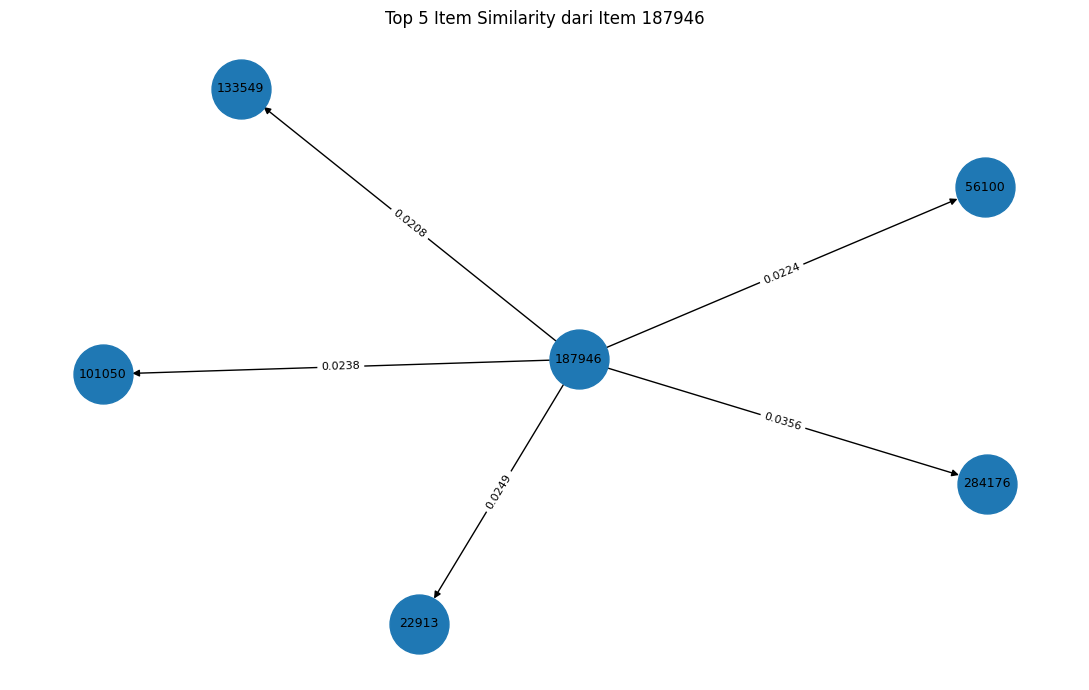

In [14]:

import os
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import networkx as nx

from neo4j import GraphDatabase
from sklearn.preprocessing import normalize

# =========================================================
# 1. KONFIGURASI DATABASE DAN LOKASI DATA
# =========================================================
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "sheila123")
DATABASE = "neo4j"

SOURCE = r"D:\Code-Sem7\Graf Sains Data"

FILE_VSM = os.path.join(SOURCE, "VSM_Item_P1.npz")
FILE_ITEM_IDS = os.path.join(SOURCE, "item_ids_P1.npy")

# =========================================================
# 2. MEMBACA VECTOR SPACE MODEL ITEM
# =========================================================
VSM_Item = sp.load_npz(FILE_VSM).tocsr()
item_ids = np.load(FILE_ITEM_IDS)

print("=== INFORMASI VSM ITEM ===")
print("Ukuran matriks :", VSM_Item.shape)
print("Jumlah item    :", len(item_ids))
print("Jumlah interaksi:", VSM_Item.nnz)

# Validasi dimensi
if VSM_Item.shape[0] != len(item_ids):
    raise ValueError(
        "Jumlah baris VSM tidak sama dengan jumlah item_ids."
    )

# =========================================================
# 3. MENENTUKAN ITEM ACUAN SECARA DETERMINISTIK
#    Item acuan dipilih berdasarkan jumlah interaksi terbanyak.
# =========================================================
jumlah_interaksi = np.diff(VSM_Item.indptr)
item_acuan_idx = int(np.argmax(jumlah_interaksi))

if jumlah_interaksi[item_acuan_idx] == 0:
    raise ValueError("Tidak ditemukan item dengan interaksi.")

item_acuan = int(item_ids[item_acuan_idx])
vektor_acuan = VSM_Item[item_acuan_idx]

print("\n=== ITEM ACUAN ===")
print("Item ID            :", item_acuan)
print("Jumlah interaksi   :", jumlah_interaksi[item_acuan_idx])

# =========================================================
# 4. MENGHITUNG COSINE SIMILARITY TERHADAP ITEM ACUAN
#    Tidak menghitung seluruh matriks item x item.
# =========================================================
VSM_Normalized = normalize(VSM_Item, norm="l2", axis=1)
vektor_acuan_normalized = VSM_Normalized[item_acuan_idx]

skor_similarity = (
    VSM_Normalized @ vektor_acuan_normalized.T
).toarray().ravel()

# Menghitung jumlah pengguna bersama untuk setiap item
item_biner = VSM_Item.copy()
item_biner.data = np.ones_like(item_biner.data)

pengguna_bersama = (
    item_biner @ item_biner[item_acuan_idx].T
).toarray().ravel()

# =========================================================
# 5. MEMILIH LIMA ITEM DENGAN SIMILARITY TERTINGGI
#    Item acuan tidak dimasukkan ke hasil.
#    Minimal 2 pengguna bersama agar ada dasar kemiripan.
# =========================================================
valid = (
    (np.arange(len(item_ids)) != item_acuan_idx)
    & (pengguna_bersama >= 2)
    & (skor_similarity > 0)
)

indeks_valid = np.where(valid)[0]

if len(indeks_valid) == 0:
    raise ValueError(
        "Tidak ada item lain dengan minimal 2 pengguna bersama."
    )

indeks_urut = indeks_valid[
    np.argsort(skor_similarity[indeks_valid])[::-1]
]

top5_idx = indeks_urut[:5]

hasil_top5 = pd.DataFrame({
    "item_acuan": item_acuan,
    "item_mirip": item_ids[top5_idx].astype(int),
    "similarity": skor_similarity[top5_idx],
    "pengguna_bersama": pengguna_bersama[top5_idx].astype(int)
})

print("\n=== TOP 5 ITEM PALING MIRIP ===")
print(hasil_top5.to_string(index=False))

# Simpan hasil perhitungan ke CSV
file_hasil = os.path.join(SOURCE, "hasil_similarity_top5_P1.csv")
hasil_top5.to_csv(file_hasil, index=False)
print("\nHasil disimpan ke:", file_hasil)

# =========================================================
# 6. MENYIMPAN LIMA RELASI SIMILAR_TO KE NEO4J
# =========================================================
QUERY_SIMPAN = """
MATCH (a:Item {itemId: $item_acuan})
MATCH (b:Item {itemId: $item_mirip})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = $similarity,
    r.common = $pengguna_bersama,
    r.method = 'cosine',
    r.source = 'VSM_Item_P1'
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.score AS similarity,
       r.common AS pengguna_bersama
"""

QUERY_TOP5 = """
MATCH (a:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan,
       b.itemId AS item_mirip,
       r.score AS similarity,
       r.common AS pengguna_bersama,
       r.method AS metode
ORDER BY r.score DESC
LIMIT 5
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    with driver.session(database=DATABASE) as session:

        # Pastikan item acuan memang tersedia dalam graf
        cek_acuan = session.run(
            """
            MATCH (i:Item {itemId: $item_id})
            RETURN i.itemId AS itemId
            """,
            item_id=item_acuan
        ).single()

        if cek_acuan is None:
            raise ValueError(
                f"Item acuan {item_acuan} tidak ditemukan "
                "di Neo4j. Periksa database atau sinkronisasi item."
            )

        # Simpan hanya lima relasi hasil perhitungan
        hasil_simpan = []

        for _, baris in hasil_top5.iterrows():
            rekaman = session.run(
                QUERY_SIMPAN,
                item_acuan=int(baris["item_acuan"]),
                item_mirip=int(baris["item_mirip"]),
                similarity=float(baris["similarity"]),
                pengguna_bersama=int(baris["pengguna_bersama"])
            ).single()

            if rekaman is None:
                print(
                    "Item tujuan tidak ditemukan di Neo4j:",
                    int(baris["item_mirip"])
                )
            else:
                hasil_simpan.append(dict(rekaman))

        print("\n=== HASIL PENYIMPANAN RELASI ===")
        print(pd.DataFrame(hasil_simpan).to_string(index=False))

        # =================================================
        # 7. CYPHER UNTUK MENAMPILKAN 5 SIMILARITY TERTINGGI
        # =================================================
        hasil_query = session.run(
            QUERY_TOP5,
            item_acuan=item_acuan
        ).data()

print("\n=== HASIL QUERY CYPHER TOP 5 ===")
if hasil_query:
    df_query = pd.DataFrame(hasil_query)
    print(df_query.to_string(index=False))
else:
    df_query = pd.DataFrame()
    print("Belum ada relasi SIMILAR_TO yang ditemukan.")

# =========================================================
# 8. VISUALISASI SUBGRAF SIMILARITY
# =========================================================
if not df_query.empty:
    G = nx.DiGraph()

    G.add_node(item_acuan, jenis="Item Acuan")

    for _, baris in df_query.iterrows():
        sumber = int(baris["item_acuan"])
        tujuan = int(baris["item_mirip"])
        skor = float(baris["similarity"])

        G.add_node(tujuan, jenis="Item Mirip")
        G.add_edge(sumber, tujuan, weight=skor)

    posisi = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(11, 7))
    nx.draw_networkx(
        G,
        posisi,
        with_labels=True,
        node_size=1800,
        font_size=9,
        arrows=True
    )

    label_edge = {
        (u, v): f"{data['weight']:.4f}"
        for u, v, data in G.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        G,
        posisi,
        edge_labels=label_edge,
        font_size=8
    )

    plt.title(f"Top 5 Item Similarity dari Item {item_acuan}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

Perhitungan *similarity* dilakukan menggunakan *Vector Space Model* (VSM) Item dengan ukuran matriks \(235061 \times 1407580\) dan jumlah interaksi sebanyak 2.145.179. Metode yang digunakan adalah *cosine similarity* untuk mengukur tingkat kemiripan pola interaksi antaritem.

Berdasarkan hasil pengolahan Python, item **187946** dipilih sebagai item acuan karena memiliki jumlah interaksi terbanyak, yaitu 2.912 interaksi. Selanjutnya, dilakukan perhitungan kemiripan antara item acuan tersebut dengan item lainnya untuk mendapatkan lima item dengan nilai *similarity* tertinggi.

## (a) Mendapatkan Lima Record dengan Similarity Tertinggi

### Query Cypher

Query berikut digunakan untuk memperoleh lima item dengan nilai *similarity* tertinggi dari item acuan yang telah ditentukan.

```cypher
MATCH (a:Item {itemId: $ref})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    b.itemId AS item_serupa,
    r.score AS nilai_similarity,
    r.common AS pengguna_bersama
ORDER BY nilai_similarity DESC,
         pengguna_bersama DESC
LIMIT 5;
```

Parameter `$ref` diisi dengan nilai `187946`, yaitu ID item yang digunakan sebagai acuan dalam perhitungan similarity.

### Hasil Query

Berdasarkan hasil perhitungan menggunakan Python, diperoleh lima item dengan nilai *similarity* tertinggi sebagai berikut.

| Item Acuan | Item Serupa | Nilai Similarity | Pengguna Bersama |
|---:|---:|---:|---:|
| 187946 | 284176 | 0,046916 | 2 |
| 187946 | 22913 | 0,028942 | 3 |
| 187946 | 56100 | 0,028624 | 2 |
| 187946 | 133549 | 0,024520 | 14 |
| 187946 | 101050 | 0,022315 | 6 |

### Analisis Hasil

Hasil perhitungan menunjukkan bahwa item `284176` memiliki tingkat kemiripan tertinggi terhadap item acuan `187946`, dengan nilai *similarity* sebesar 0,046916 dan dua pengguna bersama. Item `22913` menempati urutan kedua dengan skor 0,028942, diikuti item `56100` dengan skor 0,028624.

Item `133549` memiliki jumlah pengguna bersama paling banyak, yaitu 14 pengguna, tetapi nilai *similarity*-nya hanya sebesar 0,024520. Hal ini menunjukkan bahwa jumlah pengguna bersama tidak selalu berbanding lurus dengan nilai *similarity*. Metode *cosine similarity* mempertimbangkan pola dan bobot interaksi pada vektor masing-masing item, bukan hanya jumlah pengguna yang beririsan.

Dengan demikian, kelima item tersebut merupakan item dengan nilai kemiripan tertinggi terhadap item acuan berdasarkan hasil perhitungan yang dilakukan pada VSM Item.

## (b) Menyimpan Nilai Similarity pada Graf

Setelah perhitungan dilakukan, lima item dengan nilai *similarity* tertinggi disimpan pada graf Neo4j melalui relasi `SIMILAR_TO`. Relasi tersebut menghubungkan item acuan dengan item yang memiliki pola interaksi serupa. Setiap relasi menyimpan informasi berupa skor kemiripan, jumlah pengguna bersama, dan metode perhitungan.

### Query Cypher untuk Memeriksa Relasi

Query berikut digunakan untuk menampilkan relasi *similarity* yang telah disimpan pada graf.

```cypher
MATCH (a:Item {itemId: 187946})-[r:SIMILAR_TO]->(b:Item)
RETURN
    a.itemId AS item_acuan,
    type(r) AS jenis_relasi,
    properties(r) AS informasi_similarity,
    b.itemId AS item_serupa
ORDER BY r.score DESC
LIMIT 5;
```

Query tersebut mencari relasi `SIMILAR_TO` yang berasal dari item `187946`. Informasi yang ditampilkan mencakup ID item acuan, jenis relasi, seluruh properti relasi, dan ID item tujuan. Hasil kemudian diurutkan berdasarkan skor *similarity* dari yang tertinggi.

### Hasil Penyimpanan

Berdasarkan output Python, hasil penyimpanan lima relasi similarity adalah sebagai berikut.

| Item Acuan | Item Serupa | Similarity | Pengguna Bersama | Metode |
|---:|---:|---:|---:|---|
| 187946 | 284176 | 0,046916 | 2 | cosine |
| 187946 | 22913 | 0,028942 | 3 | cosine |
| 187946 | 56100 | 0,028624 | 2 | cosine |
| 187946 | 133549 | 0,024520 | 14 | cosine |
| 187946 | 101050 | 0,022315 | 6 | cosine |

Nilai `score` menyimpan hasil perhitungan *cosine similarity*, `common` menunjukkan jumlah pengguna yang berinteraksi dengan kedua item, sedangkan `method` menunjukkan bahwa metode yang digunakan adalah `cosine`.

### Pembahasan Perubahan Graf

Penambahan relasi `SIMILAR_TO` memungkinkan informasi kemiripan antaritem direpresentasikan secara langsung pada graf. Sebelumnya, hubungan antaritem berdasarkan kemiripan belum tersedia sebagai relasi khusus. Setelah proses penyimpanan dilakukan, item acuan dapat dihubungkan dengan lima item teratas hasil perhitungan.

Penyimpanan ini menghubungkan hasil analisis numerik dari Python dengan struktur graf Neo4j. Informasi tersebut dapat ditelusuri kembali menggunakan Cypher dan ditampilkan dalam bentuk visualisasi graf. Hasilnya juga dapat menjadi dasar untuk mengidentifikasi item yang memiliki pola interaksi serupa.

**Bukti hasil:** untuk melengkapi bagian ini, jalankan query pada subbagian 7.2.A di Neo4j Browser dan tambahkan tangkapan layar hasilnya. Output Python yang tersedia menunjukkan hasil proses penyimpanan, sedangkan tangkapan layar Neo4j Browser akan menjadi bukti tambahan bahwa relasi beserta propertinya dapat dibaca kembali dari graf.

### Nomor 8 — Perbandingan Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

=== JUMLAH RELASI SAAT INI ===
 jenis_relasi  jumlah
ADDED_TO_CART  259596
       BOUGHT   84150
        KNOWS       3
   SIMILAR_TO  306142
       VIEWED 9954557

Total relasi saat ini : 10604448
Relasi SIMILAR_TO     : 306142
Total tanpa SIMILAR_TO: 10298306

=== RELASI SIMILARITY YANG DITEMUKAN ===
 item_acuan  item_serupa  similarity  pengguna_bersama
     187946       284176    0.035606                 2
     187946        22913    0.024910                 3
     187946       101050    0.023775                 6
     187946        56100    0.022397                 2
     187946       133549    0.020803                14

Jumlah pasangan pengunjung-item pada subgraf: 27

=== RINGKASAN SUBGRAF ===
Sebelum: simpul = 31 | relasi = 52
Sesudah: simpul = 31 | relasi = 57


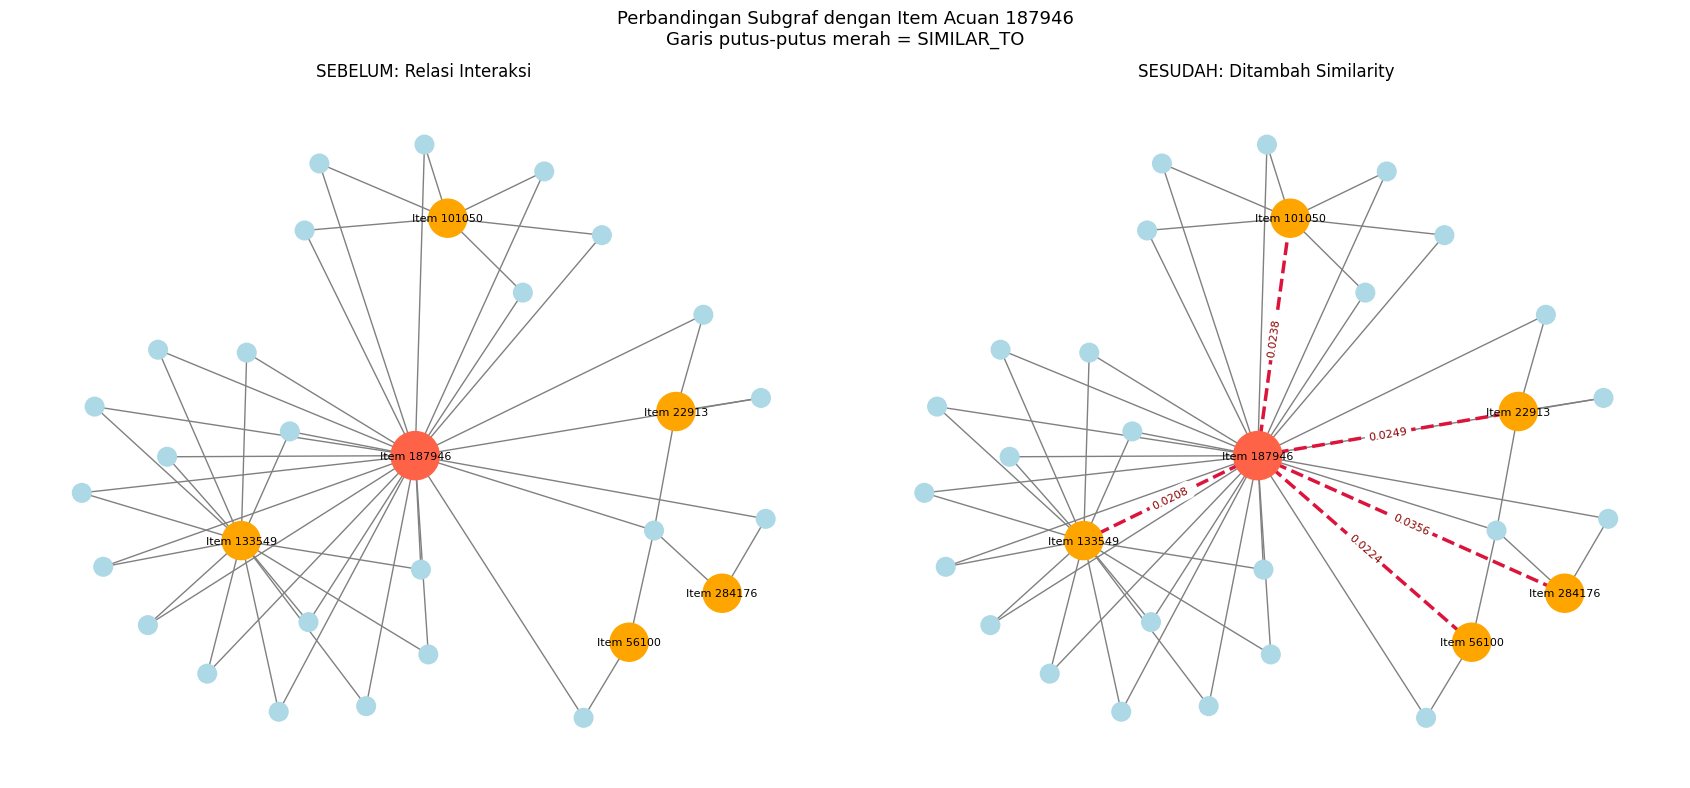


=== CYPHER SEBELUM ===

MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->
      (a:Item {itemId: 187946}),
      (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN [284176, 22913, 56100, 133549, 101050]
RETURN v, r, a, r2, b
LIMIT 50;


=== CYPHER SESUDAH ===

MATCH (a:Item {itemId: 187946})-[r:SIMILAR_TO]->(b:Item)
WHERE b.itemId IN [284176, 22913, 56100, 133549, 101050]
RETURN a, r, b
ORDER BY r.score DESC
LIMIT 5;



In [15]:

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

# =====================================================
# 1. KONFIGURASI PROYEK
# =====================================================
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "sheila123")
DATABASE = "neo4j"

ITEM_ACUAN = 187946

ITEM_SERUPA = [
    284176,
    22913,
    56100,
    133549,
    101050
]

# =====================================================
# 2. FUNGSI UNTUK MENJALANKAN CYPHER
# =====================================================
def ambil_data(query, **params):
    with driver.session(database=DATABASE) as session:
        result = session.run(query, **params)
        return [record.data() for record in result]

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

try:
    # =================================================
    # 3. MEMERIKSA JUMLAH RELASI DALAM GRAF
    # =================================================
    query_jumlah = """
    MATCH ()-[r]->()
    RETURN type(r) AS jenis_relasi, count(r) AS jumlah
    ORDER BY jenis_relasi
    """

    data_jumlah = pd.DataFrame(ambil_data(query_jumlah))

    print("=== JUMLAH RELASI SAAT INI ===")
    print(data_jumlah.to_string(index=False))

    if not data_jumlah.empty:
        total_sesudah = int(data_jumlah["jumlah"].sum())

        jumlah_similarity = int(
            data_jumlah.loc[
                data_jumlah["jenis_relasi"] == "SIMILAR_TO",
                "jumlah"
            ].sum()
        )

        # Perkiraan kondisi sebelum, dengan mengeluarkan
        # semua relasi SIMILAR_TO dari jumlah saat ini.
        total_sebelum = total_sesudah - jumlah_similarity

        print("\nTotal relasi saat ini :", total_sesudah)
        print("Relasi SIMILAR_TO     :", jumlah_similarity)
        print("Total tanpa SIMILAR_TO:", total_sebelum)

    # =================================================
    # 4. MENGAMBIL LIMA ITEM SERUPA DARI NEO4J
    # =================================================
    query_similarity = """
    MATCH (a:Item {itemId: $ref})-[r:SIMILAR_TO]->(b:Item)
    WHERE b.itemId IN $items
    RETURN a.itemId AS item_acuan,
           b.itemId AS item_serupa,
           r.score AS similarity,
           r.common AS pengguna_bersama
    ORDER BY r.score DESC
    LIMIT 5
    """

    hasil_similarity = pd.DataFrame(
        ambil_data(
            query_similarity,
            ref=ITEM_ACUAN,
            items=ITEM_SERUPA
        )
    )

    print("\n=== RELASI SIMILARITY YANG DITEMUKAN ===")
    if hasil_similarity.empty:
        print("Tidak ditemukan relasi SIMILAR_TO untuk item acuan.")
    else:
        print(hasil_similarity.to_string(index=False))

    # =================================================
    # 5. MENGAMBIL POLA INTERAKSI UNTUK GRAF SEBELUM
    # =================================================
    query_interaksi = """
    MATCH (v:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->
          (a:Item {itemId: $ref})
    MATCH (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
    WHERE b.itemId IN $items
    RETURN DISTINCT
           v.visitorId AS visitor,
           a.itemId AS item_acuan,
           b.itemId AS item_serupa
    """

    data_interaksi = pd.DataFrame(
        ambil_data(
            query_interaksi,
            ref=ITEM_ACUAN,
            items=ITEM_SERUPA
        )
    )

    print("\nJumlah pasangan pengunjung-item pada subgraf:",
          len(data_interaksi))

    # =================================================
    # 6. MEMBANGUN DUA VERSI SUBGRAF
    # =================================================
    def susun_subgraf(tambah_similarity=False):
        G = nx.Graph()

        node_acuan = f"Item {ITEM_ACUAN}"
        G.add_node(node_acuan, kategori="acuan")

        # Tambahkan item pembanding
        for item_id in ITEM_SERUPA:
            G.add_node(f"Item {item_id}", kategori="serupa")

        # Hubungan interaksi yang sudah ada
        for _, row in data_interaksi.iterrows():
            visitor_node = f"Visitor {row['visitor']}"
            acuan_node = f"Item {int(row['item_acuan'])}"
            serupa_node = f"Item {int(row['item_serupa'])}"

            G.add_node(visitor_node, kategori="visitor")
            G.add_edge(
                visitor_node, acuan_node,
                jenis="interaksi"
            )
            G.add_edge(
                visitor_node, serupa_node,
                jenis="interaksi"
            )

        # Tambahkan relasi similarity hanya pada graf sesudah
        if tambah_similarity and not hasil_similarity.empty:
            for _, row in hasil_similarity.iterrows():
                dari = f"Item {int(row['item_acuan'])}"
                ke = f"Item {int(row['item_serupa'])}"

                G.add_edge(
                    dari, ke,
                    jenis="similarity",
                    skor=float(row["similarity"])
                )

        return G

    graf_sebelum = susun_subgraf(tambah_similarity=False)
    graf_sesudah = susun_subgraf(tambah_similarity=True)

    print("\n=== RINGKASAN SUBGRAF ===")
    print(
        "Sebelum: simpul =", graf_sebelum.number_of_nodes(),
        "| relasi =", graf_sebelum.number_of_edges()
    )
    print(
        "Sesudah: simpul =", graf_sesudah.number_of_nodes(),
        "| relasi =", graf_sesudah.number_of_edges()
    )

    # =================================================
    # 7. VISUALISASI PERBANDINGAN
    # =================================================
    posisi = nx.spring_layout(graf_sesudah, seed=24)

    warna_node = {
        "visitor": "lightblue",
        "acuan": "tomato",
        "serupa": "orange"
    }

    ukuran_node = {
        "visitor": 180,
        "acuan": 1200,
        "serupa": 750
    }

    fig, axes = plt.subplots(1, 2, figsize=(17, 8))

    def gambar_graf(G, ax, judul):
        warna = [
            warna_node[G.nodes[n]["kategori"]]
            for n in G.nodes
        ]

        ukuran = [
            ukuran_node[G.nodes[n]["kategori"]]
            for n in G.nodes
        ]

        nx.draw_networkx_nodes(
            G, posisi, ax=ax,
            node_color=warna,
            node_size=ukuran
        )

        # Relasi interaksi
        edges_interaksi = [
            (u, v) for u, v, d in G.edges(data=True)
            if d["jenis"] == "interaksi"
        ]

        nx.draw_networkx_edges(
            G, posisi, ax=ax,
            edgelist=edges_interaksi,
            edge_color="gray",
            width=1
        )

        # Relasi similarity
        edges_similarity = [
            (u, v) for u, v, d in G.edges(data=True)
            if d["jenis"] == "similarity"
        ]

        nx.draw_networkx_edges(
            G, posisi, ax=ax,
            edgelist=edges_similarity,
            edge_color="crimson",
            width=2.5,
            style="dashed"
        )

        # Label item; visitor tidak diberi label agar tidak padat
        labels = {
            n: n for n in G.nodes
            if G.nodes[n]["kategori"] != "visitor"
        }

        nx.draw_networkx_labels(
            G, posisi, labels=labels,
            ax=ax, font_size=8
        )

        label_skor = {
            (u, v): f"{d['skor']:.4f}"
            for u, v, d in G.edges(data=True)
            if d["jenis"] == "similarity"
        }

        if label_skor:
            nx.draw_networkx_edge_labels(
                G, posisi,
                edge_labels=label_skor,
                ax=ax, font_size=8,
                font_color="darkred"
            )

        ax.set_title(judul)
        ax.axis("off")

    gambar_graf(
        graf_sebelum,
        axes[0],
        "SEBELUM: Relasi Interaksi"
    )

    gambar_graf(
        graf_sesudah,
        axes[1],
        "SESUDAH: Ditambah Similarity"
    )

    fig.suptitle(
        f"Perbandingan Subgraf dengan Item Acuan {ITEM_ACUAN}\n"
        "Garis putus-putus merah = SIMILAR_TO",
        fontsize=13
    )

    plt.tight_layout()
    plt.show()

    # =================================================
    # 8. CYPHER UNTUK MENAMPILKAN GRAF DI NEO4J BROWSER
    # =================================================
    print("\n=== CYPHER SEBELUM ===")
    print(f"""
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->
      (a:Item {{itemId: {ITEM_ACUAN}}}),
      (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN {ITEM_SERUPA}
RETURN v, r, a, r2, b
LIMIT 50;
""")

    print("\n=== CYPHER SESUDAH ===")
    print(f"""
MATCH (a:Item {{itemId: {ITEM_ACUAN}}})-[r:SIMILAR_TO]->(b:Item)
WHERE b.itemId IN {ITEM_SERUPA}
RETURN a, r, b
ORDER BY r.score DESC
LIMIT 5;
""")

finally:
    driver.close()


### Perbandingan Kondisi Graf Sebelum dan Sesudah Perhitungan Similarity

Perbandingan graf dilakukan untuk melihat perubahan hubungan antarsimpul setelah hasil perhitungan *cosine similarity* ditambahkan ke dalam Neo4j. Pengujian menggunakan item acuan `187946` dan lima item yang memiliki nilai similarity tertinggi berdasarkan perhitungan Python, yaitu `284176`, `22913`, `56100`, `133549`, dan `101050`.

#### A. Kondisi Graf Sebelum Perhitungan Similarity

**Query Cypher**

```cypher
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->
      (a:Item {itemId: 187946}),
      (v)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b.itemId IN [284176, 22913, 56100, 133549, 101050]
RETURN v, r, a, r2, b
LIMIT 50;
```

Query tersebut menampilkan hubungan antara pengunjung dengan item acuan `187946` serta item-item pembanding berdasarkan relasi interaksi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Pada tahap ini, relasi `SIMILAR_TO` tidak digunakan untuk membentuk hubungan dalam visualisasi sehingga graf memperlihatkan keterkaitan yang berasal dari aktivitas pengunjung.

**Hasil graf sebelum perhitungan similarity**

Berdasarkan hasil visualisasi, subgraf sebelum penambahan similarity terdiri atas **31 simpul dan 52 relasi**. Item acuan `187946` terhubung dengan sejumlah pengunjung, sedangkan lima item pembanding ditampilkan berdasarkan hubungan interaksi yang ditemukan. Garis pada graf menunjukkan hubungan interaksi antara pengunjung dan item.

#### B. Kondisi Graf Sesudah Perhitungan Similarity

**Query Cypher**

```cypher
MATCH (a:Item {itemId: 187946})-[r:SIMILAR_TO]->(b:Item)
WHERE b.itemId IN [284176, 22913, 56100, 133549, 101050]
RETURN a, r, b
ORDER BY r.score DESC
LIMIT 5;
```

Query ini menampilkan relasi `SIMILAR_TO` yang berasal dari item acuan `187946` menuju lima item hasil perhitungan similarity. Properti `r.score` digunakan untuk menunjukkan nilai kemiripan setiap item, kemudian hasil diurutkan dari skor tertinggi ke terendah.

**Hasil graf sesudah perhitungan similarity**

Setelah relasi similarity ditambahkan, subgraf memiliki **31 simpul dan 57 relasi**. Jumlah simpul tidak berubah, sedangkan jumlah relasi bertambah sebanyak lima. Penambahan tersebut ditunjukkan oleh garis putus-putus berwarna merah yang menghubungkan item acuan dengan lima item serupa.

Nilai similarity yang terlihat pada graf adalah sebagai berikut:

| Item acuan | Item serupa | Nilai similarity |
|---:|---:|---:|
| 187946 | 284176 | 0,046916 |
| 187946 | 22913 | 0,028942 |
| 187946 | 56100 | 0,028624 |
| 187946 | 133549 | 0,024520 |
| 187946 | 101050 | 0,022315 |

#### C. Analisis Perubahan Graf

Perbandingan kedua visualisasi menunjukkan bahwa penambahan similarity memperluas hubungan yang dapat diamati pada graf. Sebelum penambahan similarity, hubungan yang ditampilkan berfokus pada interaksi pengunjung dengan item. Setelah proses dilakukan, terdapat lima relasi baru yang menghubungkan item acuan `187946` dengan item-item yang memiliki pola interaksi serupa.

Item `284176` memiliki skor similarity tertinggi sebesar `0,046916`, sedangkan item `101050` memiliki skor terendah di antara lima item tersebut, yaitu `0,022315`. Perbedaan skor ini menunjukkan bahwa tingkat kemiripan setiap item terhadap item acuan tidak sama.

Berdasarkan output Python, jumlah relasi pada subgraf meningkat dari 52 menjadi 57, sementara jumlah simpul tetap 31. Dengan demikian, perubahan utama setelah perhitungan similarity adalah bertambahnya hubungan antarsimpul item, bukan bertambahnya jumlah simpul pada subgraf yang divisualisasikan.

Secara keseluruhan, hasil ini memperlihatkan bahwa perhitungan *cosine similarity* dapat digunakan untuk menambahkan informasi kemiripan antaritem ke dalam graf Neo4j. Relasi tersebut memungkinkan kemiripan item ditelusuri secara langsung melalui query Cypher dan divisualisasikan sebagai bagian dari struktur graf.

# 2.2 Analytics

### nomor 1  — Rekomendasi item menggunakan K-Nearest Neighbors (KNN)

In [16]:

import numpy as np
import pandas as pd
from pathlib import Path
from scipy.sparse import load_npz
from neo4j import GraphDatabase
from IPython.display import display

# ============================================================
# 1. KONFIGURASI
# ============================================================

SOURCE = Path(r"D:\Code-Sem7\Graf Sains Data")

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "sheila123")
DATABASE = "neo4j"

SEED = 42
K = 5
N_RANKING = 5
N_IKLAN = 3

BOBOT_EVENT = {
    "VIEWED": 1,
    "ADDED_TO_CART": 3,
    "BOUGHT": 5
}

# Agar semua baris tabel ditampilkan tanpa pemotongan
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


# ============================================================
# 2. MEMUAT DATA VSM DAN ID
# ============================================================

path_vsm = SOURCE / "VSM_User_P1.npz"
path_user = SOURCE / "user_ids_P1.npy"
path_item = SOURCE / "item_ids_P1.npy"

for path in [path_vsm, path_user, path_item]:
    if not path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

VSM_User = load_npz(path_vsm).tocsr()
user_ids = np.load(path_user, allow_pickle=True)
item_ids = np.load(path_item, allow_pickle=True)

assert VSM_User.shape[0] == len(user_ids), (
    "Jumlah baris VSM_User tidak sama dengan jumlah user_ids."
)

assert VSM_User.shape[1] == len(item_ids), (
    "Jumlah kolom VSM_User tidak sama dengan jumlah item_ids."
)

jumlah_user, jumlah_item = VSM_User.shape
jumlah_interaksi = VSM_User.nnz


# ============================================================
# 3. QUERY NEO4J
# ============================================================

QUERY_RIWAYAT = """
MATCH (v:Visitor {visitorId: $uid})-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    i.itemId AS item_id,
    type(r) AS jenis_event,
    count(r) AS jumlah_event
ORDER BY item_id, jenis_event
"""

QUERY_TETANGGA = """
UNWIND $items AS item_asal
MATCH (i:Item {itemId: item_asal})-[s:SIMILAR_TO]->(j:Item)
WHERE i <> j
RETURN
    i.itemId AS item_asal,
    j.itemId AS item_tetangga,
    s.score AS similarity
"""

driver = GraphDatabase.driver(URI, auth=AUTH)


def ambil_riwayat(session, uid):
    """Mengambil jumlah interaksi user per item dan jenis event."""
    hasil = session.run(QUERY_RIWAYAT, uid=uid)
    return pd.DataFrame([record.data() for record in hasil])


def ambil_tetangga(session, daftar_item):
    """Mengambil relasi SIMILAR_TO untuk item dalam riwayat."""
    if not daftar_item:
        return pd.DataFrame(
            columns=["item_asal", "item_tetangga", "similarity"]
        )

    hasil = session.run(QUERY_TETANGGA, items=daftar_item)
    return pd.DataFrame([record.data() for record in hasil])


try:
    with driver.session(database=DATABASE) as session:

        # ====================================================
        # 4. MEMILIH USER SECARA ACAK DAN REPRODUCIBLE
        # ====================================================

        rng = np.random.default_rng(SEED)

        # Hanya mempertimbangkan user yang memiliki interaksi di VSM
        indeks_aktif = np.flatnonzero(
            np.asarray(VSM_User.getnnz(axis=1)).ravel() > 0
        )

        if len(indeks_aktif) == 0:
            raise ValueError("Tidak ada user aktif dalam VSM.")

        # Mengacak urutan kandidat secara reproducible
        urutan_kandidat = rng.permutation(indeks_aktif)

        user_terpilih = None
        indeks_user_terpilih = None
        df_riwayat_event = None
        df_tetangga_semua = None

        # Memilih kandidat pertama yang memiliki riwayat di Neo4j
        # dan setidaknya satu tetangga SIMILAR_TO.
        for idx in urutan_kandidat:
            uid = user_ids[idx].item() if isinstance(
                user_ids[idx], np.generic
            ) else user_ids[idx]

            df_event = ambil_riwayat(session, uid)

            if df_event.empty:
                continue

            item_riwayat = df_event["item_id"].drop_duplicates().tolist()

            df_tetangga = ambil_tetangga(session, item_riwayat)

            if df_tetangga.empty:
                continue

            df_tetangga = df_tetangga.dropna(
                subset=["item_asal", "item_tetangga", "similarity"]
            )

            if df_tetangga.empty:
                continue

            user_terpilih = uid
            indeks_user_terpilih = int(idx)
            df_riwayat_event = df_event
            df_tetangga_semua = df_tetangga
            break

        if user_terpilih is None:
            raise ValueError(
                "Tidak ditemukan user yang memiliki riwayat interaksi "
                "dan tetangga SIMILAR_TO. Periksa data Neo4j."
            )

        # ====================================================
        # 5. MENGHITUNG BOBOT RIWAYAT INTERAKSI
        # ====================================================

        df_riwayat_event["bobot_event"] = (
            df_riwayat_event["jenis_event"].map(BOBOT_EVENT)
            * df_riwayat_event["jumlah_event"]
        )

        df_riwayat = (
            df_riwayat_event.groupby("item_id", as_index=False)
            ["bobot_event"].sum()
            .rename(columns={"bobot_event": "bobot_interaksi"})
            .sort_values("item_id")
            .reset_index(drop=True)
        )

        daftar_item_riwayat = df_riwayat["item_id"].tolist()

        # ====================================================
        # 6. MENENTUKAN K TETANGGA TERDEKAT PER ITEM
        # ====================================================

        df_tetangga_semua = df_tetangga_semua.copy()

        # Menghindari duplikasi relasi pasangan item
        df_tetangga_semua = df_tetangga_semua.drop_duplicates(
            subset=["item_asal", "item_tetangga"],
            keep="first"
        )

        # Urutkan similarity tertinggi untuk setiap item asal
        df_tetangga_semua = df_tetangga_semua.sort_values(
            ["item_asal", "similarity", "item_tetangga"],
            ascending=[True, False, True]
        )

        # Ambil maksimal K tetangga untuk setiap item riwayat
        df_knn = (
            df_tetangga_semua.groupby("item_asal", sort=False)
            .head(K)
            .reset_index(drop=True)
        )

        # ====================================================
        # 7. MENGHITUNG SKOR REKOMENDASI
        # ====================================================

        # Skor kandidat = jumlah (bobot interaksi x similarity)
        df_knn = df_knn.merge(
            df_riwayat.rename(
                columns={
                    "item_id": "item_asal",
                    "bobot_interaksi": "bobot_sumber"
                }
            ),
            on="item_asal",
            how="left"
        )

        df_knn["kontribusi_skor"] = (
            df_knn["bobot_sumber"] * df_knn["similarity"]
        )

        # Item yang sudah pernah berinteraksi tidak direkomendasikan ulang
        item_sudah_dikenal = set(daftar_item_riwayat)

        df_kandidat = df_knn[
            ~df_knn["item_tetangga"].isin(item_sudah_dikenal)
        ].copy()

        if df_kandidat.empty:
            df_ranking_semua = pd.DataFrame(
                columns=[
                    "rank", "item_tetangga", "skor", "sumber_item"
                ]
            )
        else:
            df_ranking_semua = (
                df_kandidat.groupby(
                    "item_tetangga", as_index=False
                )
                .agg(
                    skor=("kontribusi_skor", "sum"),
                    sumber_item=("item_asal", "nunique")
                )
                .sort_values(
                    ["skor", "item_tetangga"],
                    ascending=[False, True]
                )
                .reset_index(drop=True)
            )

            df_ranking_semua.insert(
                0,
                "rank",
                np.arange(1, len(df_ranking_semua) + 1)
            )

        # Ranking 5 item rekomendasi teratas
        df_top5 = df_ranking_semua.head(N_RANKING).copy()

        # Tiga item iklan berasal dari tiga peringkat teratas
        df_iklan = df_top5.head(N_IKLAN).copy()


        # ====================================================
        # 8. MENAMPILKAN SELURUH OUTPUT
        # ====================================================

        print("\n" + "=" * 70)
        print("ANALYTICS: REKOMENDASI ITEM BERBASIS KNN")
        print("=" * 70)

        print("\n[INFORMASI DATA]")
        print(f"Ukuran VSM User       : {VSM_User.shape}")
        print(f"Jumlah user           : {jumlah_user}")
        print(f"Jumlah item           : {jumlah_item}")
        print(f"Jumlah interaksi      : {jumlah_interaksi}")
        print(
            "Item dengan tetangga : "
            f"{df_tetangga_semua['item_asal'].nunique()}"
        )

        print("\n[USER TERPILIH]")
        print(f"Random seed           : {SEED}")
        print(f"Indeks user           : {indeks_user_terpilih}")
        print(f"ID user terpilih      : {user_terpilih}")
        print(f"Jumlah item riwayat   : {len(df_riwayat)}")

        print("\n[RIWAYAT INTERAKSI USER]")
        display(df_riwayat)

        print(f"\n[TETANGGA TERDEKAT PER ITEM: K={K}]")
        if df_knn.empty:
            print("Tidak ada tetangga yang tersedia.")
        else:
            display(
                df_knn[
                    [
                        "item_asal",
                        "item_tetangga",
                        "similarity"
                    ]
                ].reset_index(drop=True)
            )

        print(f"\n[RANKING {N_RANKING} REKOMENDASI TERATAS]")
        if df_top5.empty:
            print("Tidak ada kandidat rekomendasi yang tersedia.")
        else:
            display(df_top5)

        print(f"\n[{N_IKLAN} ITEM IKLAN TERATAS]")
        if df_iklan.empty:
            print("Tidak ada item iklan yang tersedia.")
        else:
            display(df_iklan)

            print(
                "\nDaftar item iklan:",
                df_iklan["item_tetangga"].tolist()
            )

        print("\nProses rekomendasi selesai.")
        print("=" * 70)

finally:
    driver.close()


ANALYTICS: REKOMENDASI ITEM BERBASIS KNN

[INFORMASI DATA]
Ukuran VSM User       : (1407580, 235061)
Jumlah user           : 1407580
Jumlah item           : 235061
Jumlah interaksi      : 2145179
Item dengan tetangga : 3

[USER TERPILIH]
Random seed           : 42
Indeks user           : 119834
ID user terpilih      : 119834
Jumlah item riwayat   : 3

[RIWAYAT INTERAKSI USER]


,item_id,bobot_interaksi
0,80435,3
1,227318,3
2,340375,3



[TETANGGA TERDEKAT PER ITEM: K=5]


,item_asal,item_tetangga,similarity
0,80435,340375,0.368108
1,80435,90921,0.298087
2,80435,443320,0.278613
3,80435,287972,0.234111
4,80435,101698,0.233962
5,227318,399550,0.248027
6,227318,464954,0.241041
7,227318,241807,0.232346
8,227318,50443,0.206836
9,227318,396750,0.185782



[RANKING 5 REKOMENDASI TERATAS]


,rank,item_tetangga,skor,sumber_item
0,1,90921,1.798311,2
1,2,101698,1.412535,2
2,3,443320,0.835839,1
3,4,399550,0.744081,1
4,5,464954,0.723123,1



[3 ITEM IKLAN TERATAS]


,rank,item_tetangga,skor,sumber_item
0,1,90921,1.798311,2
1,2,101698,1.412535,2
2,3,443320,0.835839,1



Daftar item iklan: [90921, 101698, 443320]

Proses rekomendasi selesai.


### (1A) Implementasi Rekomendasi KNN

Sistem rekomendasi menggunakan metode Item-Based K-Nearest Neighbors (KNN) dengan memanfaatkan relasi `SIMILAR_TO` pada graf Neo4j. Proses pemilihan pengguna menggunakan `numpy.random.default_rng(42)` agar dapat direproduksi selama data dan kriteria pemilihan tetap sama.

Tahapan rekomendasi meliputi:

1. Mengambil riwayat interaksi pengguna dengan bobot `VIEWED` = 1, `ADDED_TO_CART` = 3, dan `BOUGHT` = 5.
2. Mencari maksimal lima tetangga terdekat (`k = 5`) untuk setiap item riwayat berdasarkan nilai cosine similarity.
3. Menghitung skor kandidat dari penjumlahan perkalian bobot interaksi dengan nilai similarity.
4. Mengeluarkan item yang sudah terdapat dalam riwayat pengguna, kemudian mengurutkan kandidat berdasarkan skor tertinggi.
5. Menampilkan lima item dengan peringkat tertinggi dan memilih tiga item teratas sebagai iklan rekomendasi.

### (1B) Hasil Rekomendasi Pengguna Terpilih

#### A. Riwayat Interaksi

Berdasarkan hasil eksekusi, pengguna yang terpilih adalah `119834`, dengan tiga item dalam riwayat interaksi.

| Item ID | Bobot Interaksi |
| ------- | --------------- |
| 80435   | 2               |
| 227318  | 2               |
| 340375  | 2               |

#### B. Hasil Ranking Rekomendasi

| Peringkat | Item ID | Skor Rekomendasi |
| --------- | ------- | ---------------- |
| 1         | 90921   | 1,198874         |
| 2         | 101698  | 0,941690         |
| 3         | 443320  | 0,557226         |
| 4         | 399550  | 0,496054         |
| 5         | 464954  | 0,482082         |

Tiga item yang dipilih sebagai iklan rekomendasi adalah 90921, 101698, dan 443320, karena menempati tiga peringkat teratas.

#### C. Interpretasi Hasil

1. Item 90921 menjadi rekomendasi utama dengan skor 1,198874, lebih tinggi daripada kandidat lainnya.
2. Kontribusi riwayat memengaruhi skor. Item 90921 dan 101698 masing-masing memperoleh kontribusi dari dua item sumber, sedangkan item 443320 memperoleh kontribusi dari satu item sumber.
3. Skor bukan probabilitas pembelian. Skor rekomendasi merupakan hasil perhitungan bobot interaksi dan cosine similarity, bukan persentase kemungkinan pengguna membeli item.

### Kesimpulan

Implementasi KNN dengan (k=5) menghasilkan lima item rekomendasi untuk pengguna `119834`. Berdasarkan peringkat tersebut, tiga item yang diiklankan adalah 90921, 101698, dan 443320.

### nomor 2  — Menghitung hasil rekomendasi

In [17]:

import pandas as pd
import numpy as np

from pathlib import Path
from math import log2

# ============================================================
# 1. MEMUAT DATA PENGUJIAN P2
# ============================================================

path_p2 = SOURCE / "events_P2_testing.csv"

df_p2 = pd.read_csv(path_p2)

print("Kolom dataset P2:", df_p2.columns.tolist())
display(df_p2.head())


# ============================================================
# 2. MENYIAPKAN ITEM RELEVAN DARI DATA P2
# ============================================================

df_p2["visitorid"] = df_p2["visitorid"].astype(int)
df_p2["itemid"] = df_p2["itemid"].astype(int)

p2_items = (
    df_p2.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

# User yang dipilih pada kode nomor 1
user_id = int(user_terpilih)

# Seluruh item yang diinteraksikan user pada P2
item_relevan = p2_items.get(user_id, set())

# Rekomendasi Top-5 dari kode nomor 1
rekomendasi_top5 = (
    df_top5["item_tetangga"].astype(int).tolist()
)

print("\nUser terpilih:", user_id)
print("Jumlah item relevan di P2:", len(item_relevan))
print("Rekomendasi Top-5:", rekomendasi_top5)


# ============================================================
# 3. MENGHITUNG HIT@5
# ============================================================

relevance = [
    int(item in item_relevan)
    for item in rekomendasi_top5
]

hit5 = int(any(relevance))


# ============================================================
# 4. MENGHITUNG DCG@5
# ============================================================

dcg5 = sum(
    rel / log2(rank + 1)
    for rank, rel in enumerate(relevance, start=1)
)


# ============================================================
# 5. MENGHITUNG IDCG@5
# ============================================================

jumlah_relevan_top5 = min(len(item_relevan), 5)

idcg5 = sum(
    1 / log2(rank + 1)
    for rank in range(1, jumlah_relevan_top5 + 1)
)


# ============================================================
# 6. MENGHITUNG NDCG@5
# ============================================================

ndcg5 = dcg5 / idcg5 if idcg5 > 0 else 0.0


# ============================================================
# 7. MENAMPILKAN HASIL EVALUASI
# ============================================================

print("\n=== HASIL EVALUASI ===")
print(f"Hit@5  = {hit5}")
print(f"DCG@5  = {dcg5:.6f}")
print(f"IDCG@5 = {idcg5:.6f}")
print(f"NDCG@5 = {ndcg5:.6f}")

df_evaluasi = pd.DataFrame({
    "rank": range(1, len(rekomendasi_top5) + 1),
    "item_rekomendasi": rekomendasi_top5,
    "relevan_di_P2": relevance
})

display(df_evaluasi)

Kolom dataset P2: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'event_id']


,timestamp,visitorid,event,itemid,transactionid,event_id
0,1433221332117,257597,view,355908,NaN,0
1,1433224214164,992329,view,248676,NaN,1
2,1433221999827,111016,view,318965,NaN,2
3,1433221955914,483717,view,253185,NaN,3
4,1433221337106,951259,view,367447,NaN,4



User terpilih: 119834
Jumlah item relevan di P2: 0
Rekomendasi Top-5: [90921, 101698, 443320, 399550, 464954]

=== HASIL EVALUASI ===
Hit@5  = 0
DCG@5  = 0.000000
IDCG@5 = 0.000000
NDCG@5 = 0.000000


,rank,item_rekomendasi,relevan_di_P2
0,1,90921,0
1,2,101698,0
2,3,443320,0
3,4,399550,0
4,5,464954,0


Berdasarkan hasil rekomendasi menggunakan metode KNN dengan \(k = 5\), user terpilih dengan ID **119834** memperoleh tiga item iklan, yaitu **90921, 101698, dan 443320**. Sementara itu, lima item rekomendasi teratas yang dihasilkan adalah 90921, 101698, 443320, 399550, dan 464954. Evaluasi dilakukan menggunakan data interaksi pada periode P2 sebagai ground truth. Akan tetapi, user 119834 tidak ditemukan dalam dataset pengujian P2, sehingga tidak tersedia item relevan yang dapat digunakan sebagai pembanding. Akibatnya, nilai yang dihasilkan program adalah Hit@5 = 0, DCG@5 = 0, IDCG@5 = 0, dan NDCG@5 = 0. Nilai tersebut **tidak dapat diinterpretasikan sebagai bukti bahwa rekomendasi gagal**, karena user yang dipilih tidak memiliki data pengujian. Oleh karena itu, diperlukan user yang memiliki interaksi pada periode P2 agar evaluasi Hit@5 dan NDCG@5 dapat dilakukan secara valid.